# Machine Learning – Assignment 3
**MLPs, CNNs, Autoencoders, SVMs and Clustering on CIFAR10** · Roll no. **M26CSA008** · seed = **26008**

**How to run:** Colab → *Runtime → Change runtime type → T4 GPU* → *Runtime → Run all*. Everything (all of Q1–Q4) runs top to bottom in one go (roughly 1–1.5 hours on a T4).

Everything is saved automatically: figures in `figures/`, tables and numbers in `results/`, logs in `logs/`, model weights in `checkpoints/`. The last cell collects every number into `results/results_summary.txt`, which is what the CVPR report is written from.

Set `SMOKE_TEST=1` (environment variable) only to test the code on tiny fake data. Never use it for the real run.

In [1]:
# ---------- imports ----------
import os, json, time, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision, sklearn
from torchvision import datasets
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

# ---------- settings (change only here) ----------
ROLL_NO = "M26CSA008"
SEED = int("".join(ch for ch in ROLL_NO if ch.isdigit()))     # numeric part of roll number -> 26008
SMOKE = os.environ.get("SMOKE_TEST", "0") == "1"               # tiny fake run, only for testing the code

EPOCHS_CLS = 30        # classifiers in Q1 and Q2
EPOCHS_MEM = 150       # memorisation experiment (Q1b)
EPOCHS_AE = 30         # autoencoders (Q3)
PROBE_EPOCHS = 30      # linear probes (Q3c)
HID_SMALL = 256        # hidden width of the baseline MLP
MEM_HIDDEN = 1024      # hidden width of the high-capacity MLP (Q1b)
MEM_SUBSET = 10000     # fixed stratified subset used in Q1b
BOTTLENECKS = [32, 128, 512]   # Q3: three clearly separated bottleneck sizes
NOISE_SIGMA = 0.2      # Q3b: std of gaussian noise (pixel range 0..1)
SVM_SUBSET = 6000      # Q4: fixed stratified training subset for SVMs (chosen before model selection)
C_LIST = [0.01, 0.1, 1, 10, 100]   # Q4a: five values of C spanning four orders of magnitude
K_LIST = [5, 8, 10, 12, 15, 20]    # Q4c: candidate numbers of clusters
SVM_MAX_ITER = 200000

if SMOKE:
    EPOCHS_CLS, EPOCHS_MEM, EPOCHS_AE, PROBE_EPOCHS = 2, 4, 2, 2
    HID_SMALL, MEM_HIDDEN, MEM_SUBSET = 32, 64, 1000
    BOTTLENECKS, SVM_SUBSET, C_LIST, K_LIST, SVM_MAX_ITER = [4, 8, 16], 1000, [0.1, 1, 10], [3, 5], 20000

for folder in ["figures", "results", "logs", "checkpoints"]:
    os.makedirs(folder, exist_ok=True)

LOG_FILE = "logs/run_log.txt"
open(LOG_FILE, "w").close()
RESULTS = {}      # every important number goes in here
SUMMARY = []      # every table goes in here (written to results_summary.txt at the end)

def log(*args):
    msg = " ".join(str(a) for a in args)
    print(msg)
    with open(LOG_FILE, "a") as f:
        f.write(msg + "\n")

def add_summary(title, obj):
    text = obj.to_string(index=False) if isinstance(obj, pd.DataFrame) else str(obj)
    SUMMARY.append("=== " + title + " ===\n" + text + "\n")
    log("=== " + title + " ===\n" + text + "\n")

def save_results():
    def fix(o):
        if isinstance(o, np.integer): return int(o)
        if isinstance(o, np.floating): return float(o)
        if isinstance(o, np.ndarray): return o.tolist()
        return str(o)
    with open("results/all_results.json", "w") as f:
        json.dump(RESULTS, f, indent=2, default=fix)

def save_show(name):
    plt.tight_layout()
    plt.savefig("figures/" + name + ".png", dpi=200, bbox_inches="tight")
    plt.show()

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = "cuda" if torch.cuda.is_available() else "cpu"

log("Roll no:", ROLL_NO, "| seed:", SEED, "| smoke test:", SMOKE)
log("Device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU (this will be slow)")
log("torch", torch.__version__, "| torchvision", torchvision.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__)

Roll no: M26CSA008 | seed: 26008 | smoke test: False
Device: cuda | Tesla T4
torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | numpy 2.4.6 | sklearn 1.6.1


In [2]:
# ---------- data: CIFAR10 + the ONE fixed stratified 45000 / 5000 split ----------
if SMOKE:
    rng = np.random.RandomState(0)          # tiny fake data with a weak class signal (code test only)
    y_all = np.repeat(np.arange(10), 500)
    x_all = np.clip(rng.normal(30 + 20 * y_all[:, None, None, None], 40, (5000, 32, 32, 3)), 0, 255).astype(np.uint8)
    y_test = np.repeat(np.arange(10), 100)
    x_test = np.clip(rng.normal(30 + 20 * y_test[:, None, None, None], 40, (1000, 32, 32, 3)), 0, 255).astype(np.uint8)
    val_size = 500
    class_names = [str(i) for i in range(10)]
else:
    train_data = datasets.CIFAR10(root="./data", train=True, download=True)
    test_data = datasets.CIFAR10(root="./data", train=False, download=True)
    x_all, y_all = train_data.data, np.array(train_data.targets)
    x_test, y_test = test_data.data, np.array(test_data.targets)
    val_size = 5000
    class_names = train_data.classes

train_idx, val_idx = train_test_split(np.arange(len(y_all)), test_size=val_size, stratify=y_all, random_state=SEED)
np.savez("results/split_seed%d.npz" % SEED, train_idx=train_idx, val_idx=val_idx)   # saved split (goes in the repo)

x_train, y_train = x_all[train_idx], y_all[train_idx]
x_val, y_val = x_all[val_idx], y_all[val_idx]

def to_tensor(x):      # uint8 (N,32,32,3) -> float (N,3,32,32) in [0,1]
    return torch.from_numpy(x).permute(0, 3, 1, 2).float().div(255.0).contiguous()

X = {"train": to_tensor(x_train).to(device), "val": to_tensor(x_val).to(device), "test": to_tensor(x_test).to(device)}
Y = {"train": torch.from_numpy(y_train).long().to(device), "val": torch.from_numpy(y_val).long().to(device),
     "test": torch.from_numpy(y_test).long().to(device)}

# normalisation constants come from the TRAIN split only
MEAN = X["train"].mean(dim=(0, 2, 3))
STD = X["train"].std(dim=(0, 2, 3))

log("train", tuple(X["train"].shape), "| val", tuple(X["val"].shape), "| test", tuple(X["test"].shape))
log("train class counts:", np.bincount(y_train).tolist())
log("val class counts:  ", np.bincount(y_val).tolist())
log("MEAN", MEAN.cpu().numpy().round(4), "STD", STD.cpu().numpy().round(4))
RESULTS["setup"] = {"roll_no": ROLL_NO, "seed": SEED, "train": len(y_train), "val": len(y_val), "test": len(y_test)}

100%|██████████| 170M/170M [11:36<00:00, 245kB/s]


train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | test (10000, 3, 32, 32)
train class counts: [4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500]
val class counts:   [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
MEAN [0.4911 0.482  0.4461] STD [0.247  0.2434 0.2615]


In [3]:
# ---------- helpers used everywhere ----------
class Normalize(nn.Module):
    # normalisation lives inside the model, so data stays in [0,1]
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", mean.view(1, 3, 1, 1).clone())
        self.register_buffer("std", std.view(1, 3, 1, 1).clone())
    def forward(self, x):
        return (x - self.mean) / self.std

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def batches(x, y, bs, shuffle):
    n = len(x)
    order = torch.randperm(n, device=x.device) if shuffle else torch.arange(n, device=x.device)
    for i in range(0, n, bs):
        idx = order[i:i + bs]
        yield x[idx], (y[idx] if y is not None else None)

@torch.no_grad()
def predict_probs(model, x, bs=1000):
    model.eval()
    return torch.cat([F.softmax(model(x[i:i + bs]), dim=1) for i in range(0, len(x), bs)])

def accuracy_of(model, x, y):
    return (predict_probs(model, x).argmax(1) == y).float().mean().item()

@torch.no_grad()
def eval_loss_acc(model, x, y, bs=1000):
    model.eval()
    total_loss, correct = 0.0, 0
    for i in range(0, len(x), bs):
        out = model(x[i:i + bs])
        total_loss += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return total_loss / len(x), correct / len(x)

def train_classifier(model, xtr, ytr, xva, yva, epochs, lr=1e-3, wd=1e-4, bs=128, name="model"):
    # same recipe for every classifier: AdamW, cosine schedule, no augmentation.
    # the checkpoint with the best VALIDATION accuracy is kept.
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps_per_epoch = (len(xtr) + bs - 1) // bs
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * steps_per_epoch)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val, best_state, best_epoch = -1.0, None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in batches(xtr, ytr, bs, True):
            if len(xb) < 2:
                continue
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
        tl, ta = eval_loss_acc(model, xtr, ytr)      # train metrics measured in eval mode every epoch
        vl, va = eval_loss_acc(model, xva, yva)
        hist["train_loss"].append(tl); hist["train_acc"].append(ta)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if va > best_val:
            best_val, best_epoch = va, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if ep == 1 or ep % 5 == 0 or ep == epochs:
            log("  [%s] epoch %3d/%d | train acc %.4f | val acc %.4f | val loss %.4f | %.0fs" % (name, ep, epochs, ta, va, vl, time.time() - t0))
    model.load_state_dict(best_state)
    hist["best_epoch"], hist["best_val_acc"], hist["train_time_s"] = best_epoch, best_val, time.time() - t0
    return hist

def run_classifier(tag, maker, data_tr, data_va, epochs=None):
    epochs = epochs or EPOCHS_CLS
    set_seed()
    model = maker().to(device)
    log("--- training %s | parameters = %s" % (tag, format(count_params(model), ",")))
    hist = train_classifier(model, data_tr[0], data_tr[1], data_va[0], data_va[1], epochs, name=tag)
    torch.save(model.state_dict(), "checkpoints/%s.pt" % tag)
    return model, hist

def summarise(tag, model, hist, xte, yte):
    i = hist["best_epoch"] - 1
    return {"model": tag, "params": count_params(model), "best_epoch": hist["best_epoch"],
            "train_acc": round(hist["train_acc"][i], 4), "val_acc": round(hist["val_acc"][i], 4),
            "test_acc": round(accuracy_of(model, xte, yte), 4)}

def plot_curves(hists, title, fname):
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for name, h in hists.items():
        line, = axs[0].plot(h["val_acc"], label=name + " (val)")
        axs[0].plot(h["train_acc"], "--", color=line.get_color(), alpha=0.6, label=name + " (train)")
        line2, = axs[1].plot(h["val_loss"], label=name + " (val)")
        axs[1].plot(h["train_loss"], "--", color=line2.get_color(), alpha=0.6)
    axs[0].set_xlabel("epoch"); axs[0].set_ylabel("accuracy"); axs[0].set_title(title + " - accuracy"); axs[0].legend(fontsize=7)
    axs[1].set_xlabel("epoch"); axs[1].set_ylabel("cross-entropy"); axs[1].set_title(title + " - loss")
    save_show(fname)

def confidence_stats(probs, y, nbins=15):
    conf, pred = probs.max(1)
    correct = (pred == y).float()
    out = {"acc": correct.mean().item(), "mean_conf": conf.mean().item(),
           "conf_correct": conf[correct == 1].mean().item() if correct.sum() > 0 else float("nan"),
           "conf_wrong": conf[correct == 0].mean().item() if (1 - correct).sum() > 0 else float("nan")}
    edges = torch.linspace(0, 1, nbins + 1, device=probs.device)
    ece = 0.0
    for i in range(nbins):
        m = (conf > edges[i]) & (conf <= edges[i + 1])
        if m.any():
            ece += m.float().mean().item() * abs(correct[m].mean().item() - conf[m].mean().item())
    out["ece"] = ece
    return out

def per_class_acc(probs, y):
    pred = probs.argmax(1)
    return [(pred[y == c] == c).float().mean().item() for c in range(10)]

def img_np(t):      # one (3,32,32) tensor -> (32,32,3) numpy image for plotting
    return t.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()

In [4]:
# ---------- model definitions + the FAIRNESS CRITERION (written BEFORE any training) ----------
FAIRNESS = """
FAIRNESS CRITERION (fixed before any experiment is run)
 1. same data: same 45000/5000 split, same inputs scaling, no augmentation for any model
 2. same optimiser and budget: AdamW (lr 1e-3, wd 1e-4), cosine schedule, batch 128, same number of epochs
 3. same normalisation layers: BatchNorm in both the MLP and the CNN, ReLU everywhere
 4. parameter budget: the CNN's parameter count must be within 10% of the MLP's
 5. model selection: best-validation-accuracy checkpoint only; test set touched only for the final report
"""
log(FAIRNESS)

def make_mlp(hidden, depth=2, use_bn=True):
    layers = [Normalize(MEAN, STD), nn.Flatten()]
    d_in = 3 * 32 * 32
    for _ in range(depth):
        layers.append(nn.Linear(d_in, hidden))
        if use_bn:
            layers.append(nn.BatchNorm1d(hidden))
        layers.append(nn.ReLU())
        d_in = hidden
    layers.append(nn.Linear(d_in, 10))
    return nn.Sequential(*layers)

def make_cnn(w, use_bn=True):
    def block(cin, cout):
        ls = [nn.Conv2d(cin, cout, 3, padding=1)]
        if use_bn:
            ls.append(nn.BatchNorm2d(cout))
        ls.append(nn.ReLU())
        return ls
    layers = [Normalize(MEAN, STD)]
    layers += block(3, w) + block(w, w) + [nn.MaxPool2d(2)]              # 16x16
    layers += block(w, 2 * w) + block(2 * w, 2 * w) + [nn.MaxPool2d(2)]  # 8x8
    layers += block(2 * w, 4 * w) + [nn.MaxPool2d(2)]                    # 4x4
    layers += [nn.Flatten(), nn.Linear(4 * w * 16, 10)]
    return nn.Sequential(*layers)

def match_size(maker, target, sizes):
    # find the size whose parameter count is closest to the target
    best_s, best_p = None, None
    for s in sizes:
        p = count_params(maker(s))
        if best_p is None or abs(p - target) < abs(best_p - target):
            best_s, best_p = s, p
        if p > target:
            break
    return best_s, best_p

P_SMALL = count_params(make_mlp(HID_SMALL))
W_CNN, P_CNN = match_size(make_cnn, P_SMALL, range(2, 300))
H_LARGE, P_LARGE = match_size(make_mlp, 4 * P_SMALL, range(16, 4000, 16))

log("MLP-small : hidden %d  -> %s params" % (HID_SMALL, format(P_SMALL, ",")))
log("CNN       : width  %d  -> %s params  (%.1f%% from MLP-small)" % (W_CNN, format(P_CNN, ","), 100 * (P_CNN - P_SMALL) / P_SMALL))
log("MLP-large : hidden %d  -> %s params  (%.1fx MLP-small)" % (H_LARGE, format(P_LARGE, ","), P_LARGE / P_SMALL))
assert abs(P_CNN - P_SMALL) / P_SMALL < 0.10, "CNN is not within 10% of the MLP budget - fairness criterion violated"
RESULTS["models"] = {"mlp_small_params": P_SMALL, "cnn_params": P_CNN, "mlp_large_params": P_LARGE,
                     "mlp_small_hidden": HID_SMALL, "cnn_width": W_CNN, "mlp_large_hidden": H_LARGE}


FAIRNESS CRITERION (fixed before any experiment is run)
 1. same data: same 45000/5000 split, same inputs scaling, no augmentation for any model
 2. same optimiser and budget: AdamW (lr 1e-3, wd 1e-4), cosine schedule, batch 128, same number of epochs
 3. same normalisation layers: BatchNorm in both the MLP and the CNN, ReLU everywhere
 4. parameter budget: the CNN's parameter count must be within 10% of the MLP's
 5. model selection: best-validation-accuracy checkpoint only; test set touched only for the final report

MLP-small : hidden 256  -> 856,074 params
CNN       : width  77  -> 854,094 params  (-0.2% from MLP-small)
MLP-large : hidden 864  -> 3,414,538 params  (4.0x MLP-small)


## Q1 – Why does an MLP do poorly on CIFAR10?
**(a)** Reason chosen: **the MLP has no spatial inductive bias** (no locality, no weight sharing, so it treats the image as an unordered vector of 3072 numbers).
Rival explanation: **the MLP simply has too little capacity**.
Design: MLP-small (budget *P*), CNN with *matched* parameters (≈ *P*), and MLP-large (≈ 4×*P*).
- If capacity were the problem, MLP-large should close most of the gap to the CNN.
- If inductive bias were the problem, the parameter-matched CNN should beat even MLP-large.

In [5]:
# ---------- Q1(a): train the three comparison models ----------
data_tr, data_va = (X["train"], Y["train"]), (X["val"], Y["val"])
mlp_small, h_mlp_small = run_classifier("Q1a_MLP_small", lambda: make_mlp(HID_SMALL), data_tr, data_va)
cnn_main, h_cnn_main = run_classifier("Q1a_CNN_matched", lambda: make_cnn(W_CNN), data_tr, data_va)
mlp_large, h_mlp_large = run_classifier("Q1a_MLP_large", lambda: make_mlp(H_LARGE), data_tr, data_va)

--- training Q1a_MLP_small | parameters = 856,074
  [Q1a_MLP_small] epoch   1/30 | train acc 0.5059 | val acc 0.4750 | val loss 1.4751 | 1s
  [Q1a_MLP_small] epoch   5/30 | train acc 0.6396 | val acc 0.5278 | val loss 1.3363 | 4s
  [Q1a_MLP_small] epoch  10/30 | train acc 0.7747 | val acc 0.5622 | val loss 1.3465 | 8s
  [Q1a_MLP_small] epoch  15/30 | train acc 0.8862 | val acc 0.5522 | val loss 1.5318 | 12s
  [Q1a_MLP_small] epoch  20/30 | train acc 0.9534 | val acc 0.5474 | val loss 1.7197 | 15s
  [Q1a_MLP_small] epoch  25/30 | train acc 0.9801 | val acc 0.5458 | val loss 1.8864 | 19s
  [Q1a_MLP_small] epoch  30/30 | train acc 0.9839 | val acc 0.5486 | val loss 1.8956 | 23s
--- training Q1a_CNN_matched | parameters = 854,094
  [Q1a_CNN_matched] epoch   1/30 | train acc 0.6503 | val acc 0.6266 | val loss 1.1065 | 28s
  [Q1a_CNN_matched] epoch   5/30 | train acc 0.8885 | val acc 0.8084 | val loss 0.5901 | 147s
  [Q1a_CNN_matched] epoch  10/30 | train acc 0.9921 | val acc 0.8486 | val lo

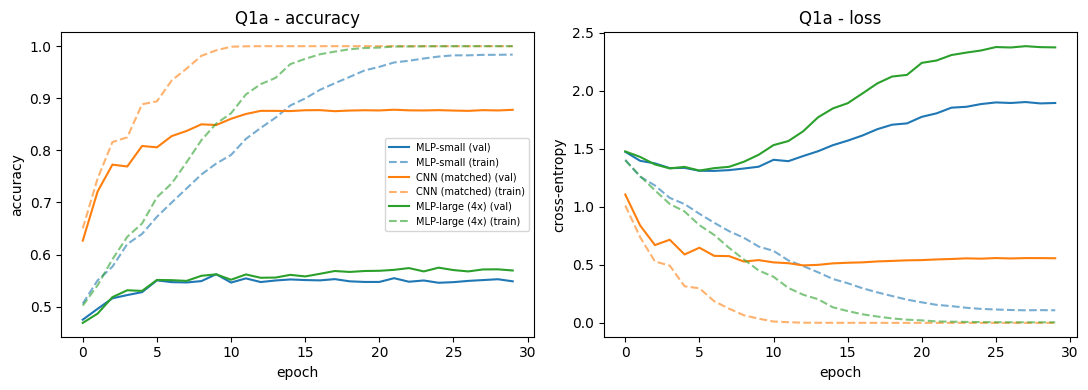

=== Q1(a) comparison table (train/val at best-val epoch, test = final) ===
                model  params  best_epoch  train_acc  val_acc  test_acc  train_val_gap
            MLP-small  856074          10     0.7747   0.5622    0.5524         0.2125
  CNN (param-matched)  854094          22     1.0000   0.8780    0.8716         0.1220
MLP-large (4x params) 3414538          25     0.9998   0.5748    0.5657         0.4250

4x more parameters improve the MLP by 1.33 points on test.
A parameter-matched CNN improves it by 31.92 points on test.
-> capacity alone explains 4% of the CNN's advantage.


In [6]:
# ---------- Q1(a): curves, table, interpretation ----------
plot_curves({"MLP-small": h_mlp_small, "CNN (matched)": h_cnn_main, "MLP-large (4x)": h_mlp_large},
            "Q1a", "q1a_curves")

rows = [summarise("MLP-small", mlp_small, h_mlp_small, X["test"], Y["test"]),
        summarise("CNN (param-matched)", cnn_main, h_cnn_main, X["test"], Y["test"]),
        summarise("MLP-large (4x params)", mlp_large, h_mlp_large, X["test"], Y["test"])]
q1a = pd.DataFrame(rows)
q1a["train_val_gap"] = (q1a["train_acc"] - q1a["val_acc"]).round(4)
add_summary("Q1(a) comparison table (train/val at best-val epoch, test = final)", q1a)
q1a.to_csv("results/q1a_table.csv", index=False)

gain_capacity = rows[2]["test_acc"] - rows[0]["test_acc"]
gain_structure = rows[1]["test_acc"] - rows[0]["test_acc"]
log("4x more parameters improve the MLP by %.2f points on test." % (100 * gain_capacity))
log("A parameter-matched CNN improves it by %.2f points on test." % (100 * gain_structure))
log("-> capacity alone explains %.0f%% of the CNN's advantage." % (100 * gain_capacity / max(gain_structure, 1e-9)))
RESULTS["Q1a"] = rows
save_results()

**(b)** Memorisation experiment. A high-capacity MLP (no BatchNorm, no weight decay, no dropout) is trained on a fixed stratified 10,000-image subset where a fraction *p* of the training labels is replaced by random labels (p = 0, 0.5, 1).
At every epoch we measure, in eval mode:
- accuracy on the **clean-labelled** training images,
- accuracy on the **randomly-labelled** images w.r.t. their *assigned random label* (= **memorisation**),
- accuracy on the same randomly-labelled images w.r.t. their *true label* (= **structure**: the network "ignores" the wrong label),
- validation accuracy (true labels).
If structure is learned first, validation accuracy and the "true label" accuracy peak early, *before* the random labels start being fitted.

In [7]:
# ---------- Q1(b): memorisation experiment ----------
sub_idx_mem, _ = train_test_split(np.arange(len(y_train)), train_size=MEM_SUBSET, stratify=y_train, random_state=SEED)
sub_t = torch.from_numpy(sub_idx_mem).to(device)
x_mem, y_mem_true = X["train"][sub_t], Y["train"][sub_t]
MEM_THRESH = 0.25     # memorisation "starts" when acc on random-labelled images (vs assigned labels) exceeds 25%
NOISE_LEVELS = [0.0, 0.5, 1.0]

def run_memorisation(p_noise):
    set_seed()
    g = torch.Generator().manual_seed(SEED)
    n = len(y_mem_true)
    flip = torch.rand(n, generator=g) < p_noise            # which images get a random label
    rand_label = torch.randint(0, 10, (n,), generator=g)
    y_given = torch.where(flip, rand_label, y_mem_true.cpu()).to(device)
    flip = flip.to(device)
    model = make_mlp(MEM_HIDDEN, depth=2, use_bn=False).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=5e-4)
    rows = []
    for ep in range(1, EPOCHS_MEM + 1):
        model.train()
        for xb, yb in batches(x_mem, y_given, 128, True):
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            out_tr, out_va = model(x_mem), model(X["val"])
            pred_tr, pred_va = out_tr.argmax(1), out_va.argmax(1)
        clean, noisy = ~flip, flip
        nan = float("nan")
        rows.append({"epoch": ep,
                     "train_loss": F.cross_entropy(out_tr, y_given).item(),
                     "train_acc_given": (pred_tr == y_given).float().mean().item(),
                     "acc_clean_labelled": (pred_tr[clean] == y_given[clean]).float().mean().item() if clean.any() else nan,
                     "acc_noisy_assigned": (pred_tr[noisy] == y_given[noisy]).float().mean().item() if noisy.any() else nan,
                     "acc_noisy_true": (pred_tr[noisy] == y_mem_true[noisy]).float().mean().item() if noisy.any() else nan,
                     "val_acc": (pred_va == Y["val"]).float().mean().item(),
                     "val_loss": F.cross_entropy(out_va, Y["val"]).item()})
        if ep == 1 or ep % 25 == 0 or ep == EPOCHS_MEM:
            r = rows[-1]
            log("  [p=%.1f] epoch %3d | train acc %.3f | val acc %.3f" % (p_noise, ep, r["train_acc_given"], r["val_acc"]))
    test_acc_final = accuracy_of(model, X["test"], Y["test"])
    return pd.DataFrame(rows), count_params(model), test_acc_final

mem_runs, mem_summary = {}, []
for p in NOISE_LEVELS:
    log("--- memorisation run, fraction of random labels p = %.1f" % p)
    df, n_params, test_final = run_memorisation(p)
    mem_runs[p] = df
    df.to_csv("results/q1b_curves_p%d.csv" % int(p * 100), index=False)
    peak_row = df.loc[df["val_acc"].idxmax()]
    hits = df[df["acc_noisy_assigned"] > MEM_THRESH]
    mem_start = int(hits["epoch"].iloc[0]) if len(hits) else None
    fit99 = df[df["train_acc_given"] >= 0.99]
    mem_summary.append({"p_random_labels": p, "params": n_params, "peak_val_acc": round(peak_row["val_acc"], 4),
                        "peak_val_epoch": int(peak_row["epoch"]), "final_val_acc": round(df["val_acc"].iloc[-1], 4),
                        "memorisation_start_epoch": mem_start,
                        "epoch_train_acc_99": int(fit99["epoch"].iloc[0]) if len(fit99) else None,
                        "final_train_acc": round(df["train_acc_given"].iloc[-1], 4),
                        "final_test_acc": round(test_final, 4)})
mem_table = pd.DataFrame(mem_summary)
add_summary("Q1(b) memorisation summary", mem_table)
mem_table.to_csv("results/q1b_summary.csv", index=False)
RESULTS["Q1b"] = mem_summary
save_results()

--- memorisation run, fraction of random labels p = 0.0
  [p=0.0] epoch   1 | train acc 0.454 | val acc 0.396
  [p=0.0] epoch  25 | train acc 0.954 | val acc 0.454
  [p=0.0] epoch  50 | train acc 1.000 | val acc 0.478
  [p=0.0] epoch  75 | train acc 1.000 | val acc 0.474
  [p=0.0] epoch 100 | train acc 1.000 | val acc 0.474
  [p=0.0] epoch 125 | train acc 1.000 | val acc 0.475
  [p=0.0] epoch 150 | train acc 1.000 | val acc 0.477
--- memorisation run, fraction of random labels p = 0.5
  [p=0.5] epoch   1 | train acc 0.268 | val acc 0.342
  [p=0.5] epoch  25 | train acc 0.997 | val acc 0.297
  [p=0.5] epoch  50 | train acc 1.000 | val acc 0.297
  [p=0.5] epoch  75 | train acc 1.000 | val acc 0.299
  [p=0.5] epoch 100 | train acc 1.000 | val acc 0.298
  [p=0.5] epoch 125 | train acc 1.000 | val acc 0.300
  [p=0.5] epoch 150 | train acc 1.000 | val acc 0.297
--- memorisation run, fraction of random labels p = 1.0
  [p=1.0] epoch   1 | train acc 0.129 | val acc 0.100
  [p=1.0] epoch  25 | 

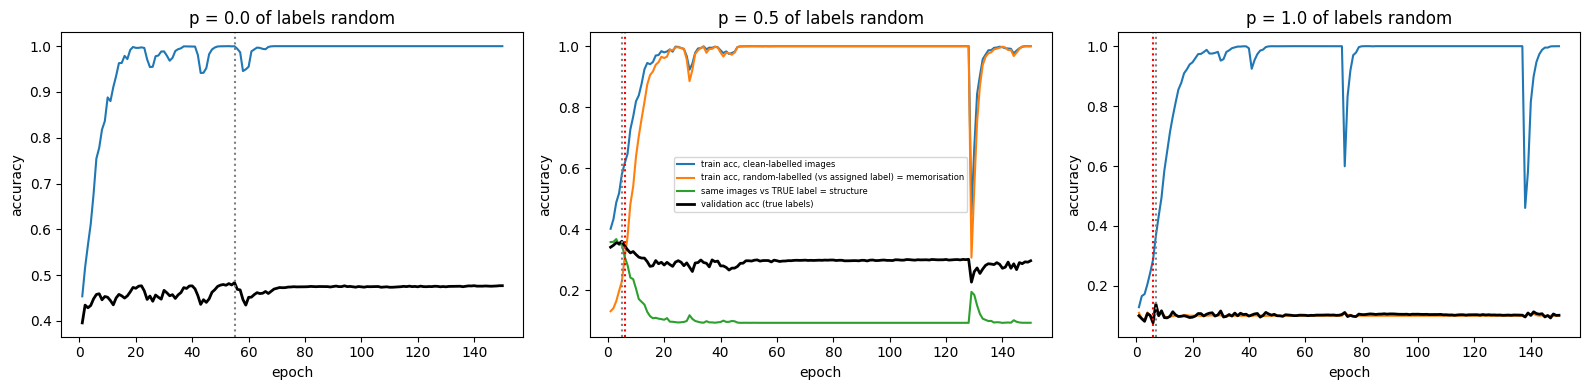

p=0.5: validation accuracy peaked at epoch 5, BEFORE memorisation began (epoch 6) -> structure first, memorisation later.
p=1.0: validation peak (epoch 7) is not earlier than memorisation start (epoch 6).


In [8]:
# ---------- Q1(b): figure + verdict ----------
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, p in zip(axs, NOISE_LEVELS):
    df = mem_runs[p]
    if p < 1.0:
        ax.plot(df["epoch"], df["acc_clean_labelled"], label="train acc, clean-labelled images")
    if p > 0.0:
        ax.plot(df["epoch"], df["acc_noisy_assigned"], label="train acc, random-labelled (vs assigned label) = memorisation")
        ax.plot(df["epoch"], df["acc_noisy_true"], label="same images vs TRUE label = structure")
    ax.plot(df["epoch"], df["val_acc"], "k", linewidth=2, label="validation acc (true labels)")
    s = mem_table[mem_table["p_random_labels"] == p].iloc[0]
    ax.axvline(s["peak_val_epoch"], color="gray", linestyle=":")
    if s["memorisation_start_epoch"] is not None and not pd.isna(s["memorisation_start_epoch"]):
        ax.axvline(s["memorisation_start_epoch"], color="red", linestyle=":")
    ax.set_title("p = %.1f of labels random" % p); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy")
    if p == 0.5:
        ax.legend(fontsize=6)
save_show("q1b_memorisation")

for s in mem_summary:
    if s["p_random_labels"] == 0.0:
        continue
    if s["memorisation_start_epoch"] is None:
        log("p=%.1f: memorisation (>%.0f%% on random-labelled images) had not started within %d epochs." % (s["p_random_labels"], 100 * MEM_THRESH, EPOCHS_MEM))
    elif s["peak_val_epoch"] < s["memorisation_start_epoch"]:
        log("p=%.1f: validation accuracy peaked at epoch %d, BEFORE memorisation began (epoch %d) -> structure first, memorisation later." % (s["p_random_labels"], s["peak_val_epoch"], s["memorisation_start_epoch"]))
    else:
        log("p=%.1f: validation peak (epoch %d) is not earlier than memorisation start (epoch %d)." % (s["p_random_labels"], s["peak_val_epoch"], s["memorisation_start_epoch"]))

## Q2 – CNN vs MLP, spatial structure, and one extra experiment
**(a)** Fair comparison = the CNN and MLP-small from Q1(a) (*reused from Q1(a)*), under the criterion printed above (written before training).
Proposed reason for the gap: the CNN's **local connectivity + weight sharing (spatial inductive bias)**.

**(b)** Same pixel values, spatial structure destroyed: one fixed random permutation of the 32×32 pixel positions (same permutation for every image and channel, applied identically to train, validation and test). Both models are retrained.

In [9]:
# ---------- Q2(a): fair comparison (models reused from Q1a) ----------
q2a = q1a[q1a["model"].isin(["MLP-small", "CNN (param-matched)"])].copy()
q2a["source"] = "reused from Q1(a)"
add_summary("Q2(a) CNN vs MLP", q2a)
mlp_acc = float(q2a[q2a["model"] == "MLP-small"]["test_acc"].iloc[0])
cnn_acc = float(q2a[q2a["model"] == "CNN (param-matched)"]["test_acc"].iloc[0])
log("Parameter ratio CNN/MLP = %.3f (criterion: within 10%%)" % (P_CNN / P_SMALL))
log("Observed: CNN beats the MLP by %.2f points at (almost) equal parameters; 4x larger MLP only closes %.0f%% of that gap." %
    (100 * (cnn_acc - mlp_acc), 100 * gain_capacity / max(gain_structure, 1e-9)))
PROPOSED_REASON = "The CNN's advantage comes from its spatial inductive bias (local connectivity and weight sharing): it can use which pixels are neighbours, while the MLP cannot."
log("Proposed reason:", PROPOSED_REASON)
RESULTS["Q2a"] = {"mlp_test": mlp_acc, "cnn_test": cnn_acc, "param_ratio": P_CNN / P_SMALL, "reason": PROPOSED_REASON}

=== Q2(a) CNN vs MLP ===
              model  params  best_epoch  train_acc  val_acc  test_acc  train_val_gap            source
          MLP-small  856074          10     0.7747   0.5622    0.5524         0.2125 reused from Q1(a)
CNN (param-matched)  854094          22     1.0000   0.8780    0.8716         0.1220 reused from Q1(a)

Parameter ratio CNN/MLP = 0.998 (criterion: within 10%)
Observed: CNN beats the MLP by 31.92 points at (almost) equal parameters; 4x larger MLP only closes 4% of that gap.
Proposed reason: The CNN's advantage comes from its spatial inductive bias (local connectivity and weight sharing): it can use which pixels are neighbours, while the MLP cannot.



EXPECTATION (written before retraining):
 - MLP: roughly unchanged. A fully connected layer has no notion of neighbourhood, so a fixed pixel permutation
   only relabels input coordinates (statistically the same problem).
 - CNN: clearly worse, because its local 3x3 filters now see unrelated pixels and weight sharing is meaningless.
 - If the part (a) explanation is right, the CNN advantage should shrink strongly or vanish.



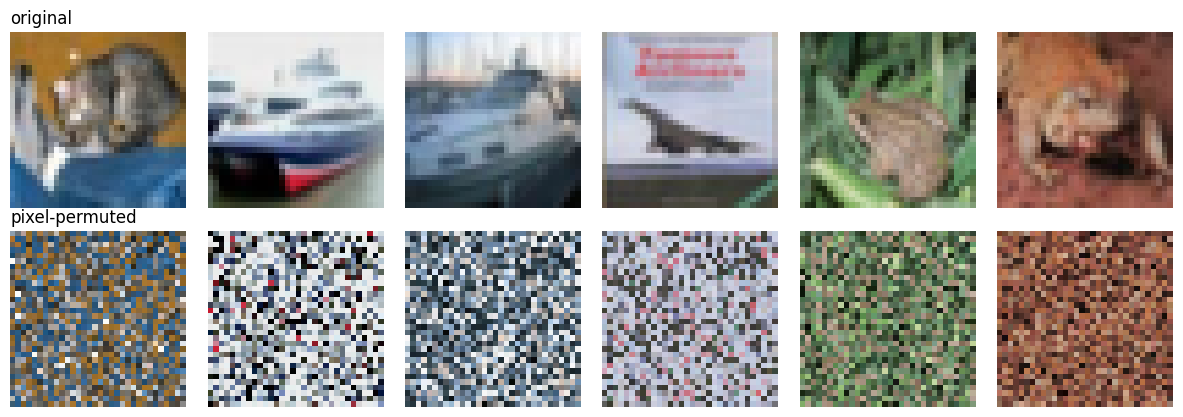

--- training Q2b_MLP_perm | parameters = 856,074
  [Q2b_MLP_perm] epoch   1/30 | train acc 0.5083 | val acc 0.4718 | val loss 1.4709 | 1s
  [Q2b_MLP_perm] epoch   5/30 | train acc 0.6417 | val acc 0.5324 | val loss 1.3341 | 4s
  [Q2b_MLP_perm] epoch  10/30 | train acc 0.7760 | val acc 0.5588 | val loss 1.3746 | 8s
  [Q2b_MLP_perm] epoch  15/30 | train acc 0.8845 | val acc 0.5468 | val loss 1.5707 | 12s
  [Q2b_MLP_perm] epoch  20/30 | train acc 0.9529 | val acc 0.5464 | val loss 1.7502 | 15s
  [Q2b_MLP_perm] epoch  25/30 | train acc 0.9802 | val acc 0.5422 | val loss 1.8977 | 19s
  [Q2b_MLP_perm] epoch  30/30 | train acc 0.9836 | val acc 0.5426 | val loss 1.9188 | 23s
--- training Q2b_CNN_perm | parameters = 854,094
  [Q2b_CNN_perm] epoch   1/30 | train acc 0.3316 | val acc 0.3274 | val loss 1.8141 | 34s
  [Q2b_CNN_perm] epoch   5/30 | train acc 0.6561 | val acc 0.5336 | val loss 1.3671 | 162s
  [Q2b_CNN_perm] epoch  10/30 | train acc 0.9702 | val acc 0.5266 | val loss 2.0648 | 324s
  [

In [10]:
# ---------- Q2(b): expectation (written BEFORE training), then pixel-permuted data ----------
EXPECTATION_B = """
EXPECTATION (written before retraining):
 - MLP: roughly unchanged. A fully connected layer has no notion of neighbourhood, so a fixed pixel permutation
   only relabels input coordinates (statistically the same problem).
 - CNN: clearly worse, because its local 3x3 filters now see unrelated pixels and weight sharing is meaningless.
 - If the part (a) explanation is right, the CNN advantage should shrink strongly or vanish.
"""
log(EXPECTATION_B)

perm = np.random.RandomState(SEED).permutation(32 * 32)       # one fixed permutation, derived from the seed
perm_t = torch.from_numpy(perm).to(device)
np.save("results/pixel_permutation.npy", perm)

def shuffle_pixels(x):          # same permutation for every image and every colour channel
    n = x.shape[0]
    return x.reshape(n, 3, 32 * 32)[:, :, perm_t].reshape(n, 3, 32, 32).contiguous()

Xp = {k: shuffle_pixels(v) for k, v in X.items()}      # applied identically to train, val and test

fig, axs = plt.subplots(2, 6, figsize=(12, 4.2))
for j in range(6):
    axs[0, j].imshow(img_np(X["test"][j])); axs[0, j].axis("off")
    axs[1, j].imshow(img_np(Xp["test"][j])); axs[1, j].axis("off")
axs[0, 0].set_title("original", loc="left"); axs[1, 0].set_title("pixel-permuted", loc="left")
save_show("q2b_permuted_examples")

mlp_perm, h_mlp_perm = run_classifier("Q2b_MLP_perm", lambda: make_mlp(HID_SMALL), (Xp["train"], Y["train"]), (Xp["val"], Y["val"]))
cnn_perm, h_cnn_perm = run_classifier("Q2b_CNN_perm", lambda: make_cnn(W_CNN), (Xp["train"], Y["train"]), (Xp["val"], Y["val"]))

=== Q2(b) models trained and tested on pixel-permuted CIFAR10 ===
               model  params  best_epoch  train_acc  val_acc  test_acc
MLP-small (permuted)  856074          10      0.776   0.5588    0.5517
      CNN (permuted)  854094          14      1.000   0.5632    0.5592

MLP: clean 0.5524 -> permuted 0.5517 (change -0.07 points)
CNN: clean 0.8716 -> permuted 0.5592 (change -31.24 points)
CNN minus MLP advantage: clean +31.92 points -> permuted +0.75 points
-> matches the expectation: MLP unaffected, CNN loses most of its advantage. Supports the spatial-structure explanation.


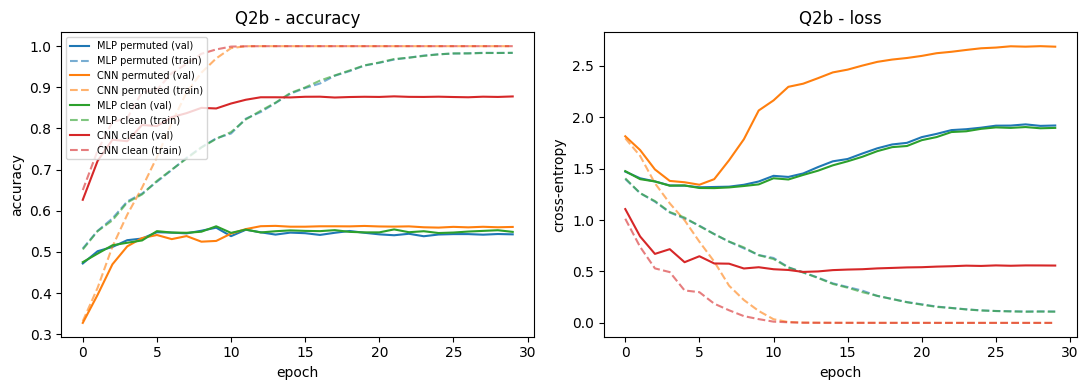

In [11]:
# ---------- Q2(b): results ----------
rows_perm = [summarise("MLP-small (permuted)", mlp_perm, h_mlp_perm, Xp["test"], Y["test"]),
             summarise("CNN (permuted)", cnn_perm, h_cnn_perm, Xp["test"], Y["test"])]
q2b = pd.DataFrame(rows_perm)
add_summary("Q2(b) models trained and tested on pixel-permuted CIFAR10", q2b)

mlp_p, cnn_p = rows_perm[0]["test_acc"], rows_perm[1]["test_acc"]
log("MLP: clean %.4f -> permuted %.4f (change %+.2f points)" % (mlp_acc, mlp_p, 100 * (mlp_p - mlp_acc)))
log("CNN: clean %.4f -> permuted %.4f (change %+.2f points)" % (cnn_acc, cnn_p, 100 * (cnn_p - cnn_acc)))
log("CNN minus MLP advantage: clean %+.2f points -> permuted %+.2f points" % (100 * (cnn_acc - mlp_acc), 100 * (cnn_p - mlp_p)))
if abs(mlp_p - mlp_acc) < 0.03 and (cnn_acc - cnn_p) > 0.10:
    log("-> matches the expectation: MLP unaffected, CNN loses most of its advantage. Supports the spatial-structure explanation.")
else:
    log("-> does NOT cleanly match the expectation; discuss honestly in the report.")
plot_curves({"MLP permuted": h_mlp_perm, "CNN permuted": h_cnn_perm, "MLP clean": h_mlp_small, "CNN clean": h_cnn_main},
            "Q2b", "q2b_curves")
RESULTS["Q2b"] = {"mlp_perm_test": mlp_p, "cnn_perm_test": cnn_p, "mlp_clean_test": mlp_acc, "cnn_clean_test": cnn_acc}
del Xp
torch.cuda.empty_cache()
save_results()

**(c)** One further experiment, to separate two explanations of *what the CNN uses*:
- **H1 – colour statistics:** the CNN mostly exploits colour cues (blue sky → airplane, green → frog, ...).
- **H2 – shape / texture structure:** the CNN mostly exploits spatial structure and would barely care about colour.

Experiment: **grayscale conversion** (luminance, replicated to 3 channels so the architecture and parameter counts are unchanged), applied identically to train, validation and test. We retrain CNN and MLP on grayscale, and also test the colour-trained CNN on grayscale test images without retraining.
Prediction (before running): under H2 the retrained CNN loses only a few points; under H1 it loses a lot, mainly on colour-cued classes.

Prediction: H2 (structure) -> grayscale-retrained CNN loses only a few points; drops concentrated in colour-cued classes (airplane, ship, frog, deer). H1 (colour) would give a large overall drop.
--- training Q2c_CNN_gray | parameters = 854,094
  [Q2c_CNN_gray] epoch   1/30 | train acc 0.6689 | val acc 0.6482 | val loss 1.0075 | 33s
  [Q2c_CNN_gray] epoch   5/30 | train acc 0.9061 | val acc 0.8092 | val loss 0.5842 | 161s
  [Q2c_CNN_gray] epoch  10/30 | train acc 0.9958 | val acc 0.8358 | val loss 0.6174 | 323s
  [Q2c_CNN_gray] epoch  15/30 | train acc 1.0000 | val acc 0.8496 | val loss 0.6128 | 484s
  [Q2c_CNN_gray] epoch  20/30 | train acc 1.0000 | val acc 0.8480 | val loss 0.6525 | 646s
  [Q2c_CNN_gray] epoch  25/30 | train acc 1.0000 | val acc 0.8496 | val loss 0.6729 | 808s
  [Q2c_CNN_gray] epoch  30/30 | train acc 1.0000 | val acc 0.8490 | val loss 0.6799 | 969s
--- training Q2c_MLP_gray | parameters = 856,074
  [Q2c_MLP_gray] epoch   1/30 | train acc 0.4174 | val acc 0.4010 | va

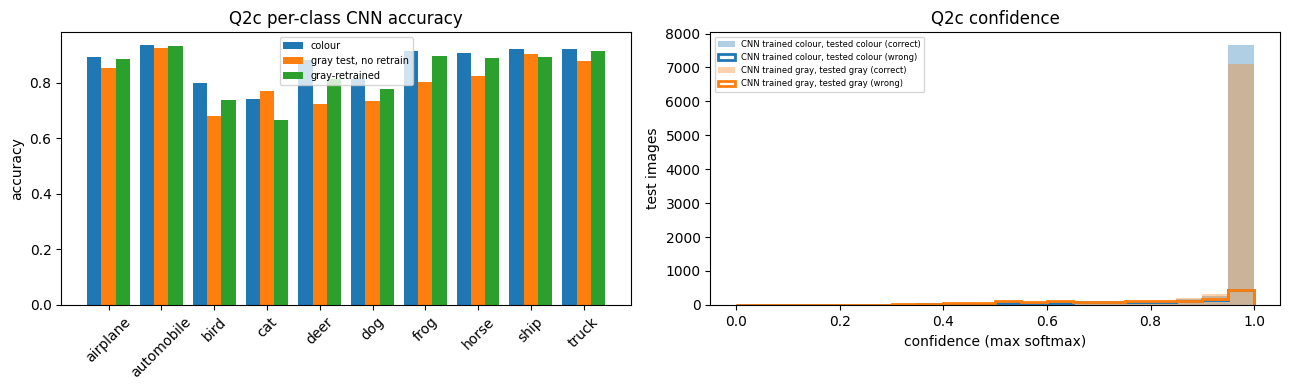


LINKING NUMBERS: (a) CNN-MLP gap on clean data +31.92 points | (b) same gap on pixel-permuted data +0.75 points | (c) CNN drop when colour is removed 3.25 points.


In [12]:
# ---------- Q2(c): grayscale experiment ----------
EXPECTATION_C = "Prediction: H2 (structure) -> grayscale-retrained CNN loses only a few points; drops concentrated in colour-cued classes (airplane, ship, frog, deer). H1 (colour) would give a large overall drop."
log(EXPECTATION_C)

def to_gray(x):
    g = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
    return g.repeat(1, 3, 1, 1).contiguous()

Xg = {k: to_gray(v) for k, v in X.items()}      # same transformation for train, val and test

cnn_gray, h_cnn_gray = run_classifier("Q2c_CNN_gray", lambda: make_cnn(W_CNN), (Xg["train"], Y["train"]), (Xg["val"], Y["val"]))
mlp_gray, h_mlp_gray = run_classifier("Q2c_MLP_gray", lambda: make_mlp(HID_SMALL), (Xg["train"], Y["train"]), (Xg["val"], Y["val"]))

yt = Y["test"]
probs = {"CNN trained colour, tested colour": predict_probs(cnn_main, X["test"]),
         "CNN trained colour, tested gray (no retraining)": predict_probs(cnn_main, Xg["test"]),
         "CNN trained gray, tested gray": predict_probs(cnn_gray, Xg["test"]),
         "MLP trained colour, tested colour": predict_probs(mlp_small, X["test"]),
         "MLP trained gray, tested gray": predict_probs(mlp_gray, Xg["test"])}
rows_c = []
for name, pr in probs.items():
    st = confidence_stats(pr, yt)
    rows_c.append({"condition": name, "test_acc": round(st["acc"], 4), "mean_conf": round(st["mean_conf"], 4),
                   "conf_when_correct": round(st["conf_correct"], 4), "conf_when_wrong": round(st["conf_wrong"], 4),
                   "ECE": round(st["ece"], 4)})
q2c = pd.DataFrame(rows_c)
add_summary("Q2(c) grayscale experiment: accuracy and confidence (test set)", q2c)
RESULTS["Q2c"] = rows_c

# per-class view for the CNN
pc_color = per_class_acc(probs["CNN trained colour, tested colour"], yt)
pc_gray_noretrain = per_class_acc(probs["CNN trained colour, tested gray (no retraining)"], yt)
pc_gray = per_class_acc(probs["CNN trained gray, tested gray"], yt)
pc_table = pd.DataFrame({"class": class_names, "colour": np.round(pc_color, 3), "gray_noretrain": np.round(pc_gray_noretrain, 3),
                         "gray_retrained": np.round(pc_gray, 3)})
pc_table["drop_retrained"] = (pc_table["colour"] - pc_table["gray_retrained"]).round(3)
add_summary("Q2(c) per-class CNN accuracy", pc_table)
RESULTS["Q2c_per_class"] = pc_table.to_dict(orient="list")

# how many images flip between right and wrong
right_col = probs["CNN trained colour, tested colour"].argmax(1) == yt
right_gray = probs["CNN trained gray, tested gray"].argmax(1) == yt
log("Of images the colour CNN got right, %.1f%% become wrong in the gray CNN; of images it got wrong, %.1f%% become right." %
    (100 * (right_col & ~right_gray).sum().item() / right_col.sum().item(), 100 * (~right_col & right_gray).sum().item() / (~right_col).sum().item()))

acc_c, acc_g = rows_c[0]["test_acc"], rows_c[2]["test_acc"]
log("Overall: colour CNN %.4f -> gray-retrained CNN %.4f (drop %.2f points)" % (acc_c, acc_g, 100 * (acc_c - acc_g)))
log("Biggest per-class drops:", pc_table.sort_values("drop_retrained", ascending=False).head(3)[["class", "drop_retrained"]].values.tolist())

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
xs = np.arange(10)
axs[0].bar(xs - 0.27, pc_color, 0.27, label="colour"); axs[0].bar(xs, pc_gray_noretrain, 0.27, label="gray test, no retrain")
axs[0].bar(xs + 0.27, pc_gray, 0.27, label="gray-retrained")
axs[0].set_xticks(xs); axs[0].set_xticklabels(class_names, rotation=45); axs[0].set_ylabel("accuracy"); axs[0].set_title("Q2c per-class CNN accuracy"); axs[0].legend(fontsize=7)
for name, color in [("CNN trained colour, tested colour", "tab:blue"), ("CNN trained gray, tested gray", "tab:orange")]:
    conf, pred = probs[name].max(1)
    ok = (pred == yt)
    axs[1].hist(conf[ok].cpu().numpy(), bins=20, range=(0, 1), alpha=0.35, color=color, label=name + " (correct)")
    axs[1].hist(conf[~ok].cpu().numpy(), bins=20, range=(0, 1), histtype="step", linewidth=2, color=color, label=name + " (wrong)")
axs[1].set_xlabel("confidence (max softmax)"); axs[1].set_ylabel("test images"); axs[1].set_title("Q2c confidence"); axs[1].legend(fontsize=6)
save_show("q2c_gray_analysis")

# numbers for the concluding paragraph linking Q2(a), (b), (c)
log("\nLINKING NUMBERS: (a) CNN-MLP gap on clean data %+.2f points | (b) same gap on pixel-permuted data %+.2f points | (c) CNN drop when colour is removed %.2f points." %
    (100 * (cnn_acc - mlp_acc), 100 * (cnn_p - mlp_p), 100 * (acc_c - acc_g)))
del Xg
torch.cuda.empty_cache()
save_results()

## Q3 – Convolutional autoencoders
**(a)** Three CNN autoencoders that differ **only in bottleneck size** *d* = 32, 128, 512 (compression 96×, 24×, 6×). Same conv layers, same optimiser (Adam, lr 1e-3), same epochs, MSE loss on [0,1] pixels. Selection by validation reconstruction error only.

--- training clean AE with bottleneck d = 32 | parameters = 464,227
  [AE_d32] epoch   1/30 | train mse 0.02935 | val mse 0.01840 | 3s
  [AE_d32] epoch   5/30 | train mse 0.01260 | val mse 0.01255 | 13s
  [AE_d32] epoch  10/30 | train mse 0.01178 | val mse 0.01235 | 26s
  [AE_d32] epoch  15/30 | train mse 0.01153 | val mse 0.01161 | 38s
  [AE_d32] epoch  20/30 | train mse 0.01138 | val mse 0.01157 | 51s
  [AE_d32] epoch  25/30 | train mse 0.01124 | val mse 0.01148 | 63s
  [AE_d32] epoch  30/30 | train mse 0.01114 | val mse 0.01150 | 75s
--- training clean AE with bottleneck d = 128 | parameters = 857,539
  [AE_d128] epoch   1/30 | train mse 0.02411 | val mse 0.01404 | 3s
  [AE_d128] epoch   5/30 | train mse 0.00790 | val mse 0.00843 | 13s
  [AE_d128] epoch  10/30 | train mse 0.00585 | val mse 0.00581 | 26s
  [AE_d128] epoch  15/30 | train mse 0.00517 | val mse 0.00524 | 39s
  [AE_d128] epoch  20/30 | train mse 0.00493 | val mse 0.00505 | 52s
  [AE_d128] epoch  25/30 | train mse 0.00483

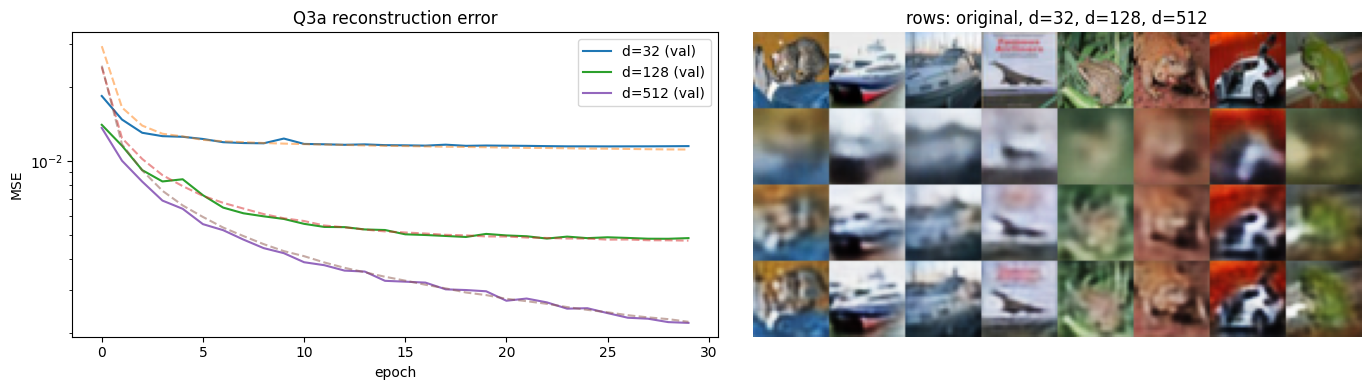

In [13]:
# ---------- Q3(a): three autoencoders ----------
class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc_conv = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(),       # 16x16
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),      # 8x8
            nn.Conv2d(64, 128, 4, 2, 1), nn.ReLU(),     # 4x4
            nn.Flatten())
        self.enc_fc = nn.Linear(128 * 4 * 4, d)         # the bottleneck (d numbers per image)
        self.dec_fc = nn.Linear(d, 128 * 4 * 4)
        self.dec_conv = nn.Sequential(
            nn.ReLU(), nn.Unflatten(1, (128, 4, 4)),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid())
    def encode(self, x):
        return self.enc_fc(self.enc_conv(x))
    def decode(self, z):
        return self.dec_conv(self.dec_fc(z))
    def forward(self, x):
        return self.decode(self.encode(x))

@torch.no_grad()
def recon(ae, x_in, bs=1000):
    ae.eval()
    return torch.cat([ae(x_in[i:i + bs]) for i in range(0, len(x_in), bs)])

def recon_mse(ae, x_target, x_in=None):
    x_in = x_target if x_in is None else x_in
    return F.mse_loss(recon(ae, x_in), x_target).item()

def train_ae(ae, xtr, xva, epochs, corrupt=None, xva_in=None, lr=1e-3, bs=128, tag="ae"):
    # corrupt=None -> normal autoencoder; corrupt=function -> denoising autoencoder (no labels used anywhere)
    opt = torch.optim.Adam(ae.parameters(), lr=lr)
    xva_in = xva if xva_in is None else xva_in
    hist = {"train_mse": [], "val_mse": []}
    best_val, best_state, best_epoch = 1e9, None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        ae.train()
        total, seen = 0.0, 0
        for xb, _ in batches(xtr, None, bs, True):
            inp = corrupt(xb) if corrupt is not None else xb
            loss = F.mse_loss(ae(inp), xb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.detach() * len(xb)
            seen += len(xb)
        val_mse = recon_mse(ae, xva, xva_in)
        hist["train_mse"].append(float(total) / seen)
        hist["val_mse"].append(val_mse)
        if val_mse < best_val:
            best_val, best_epoch = val_mse, ep
            best_state = {k: v.detach().clone() for k, v in ae.state_dict().items()}
        if ep == 1 or ep % 5 == 0 or ep == epochs:
            log("  [%s] epoch %3d/%d | train mse %.5f | val mse %.5f | %.0fs" % (tag, ep, epochs, hist["train_mse"][-1], val_mse, time.time() - t0))
    ae.load_state_dict(best_state)
    hist["best_epoch"], hist["best_val_mse"] = best_epoch, best_val
    return hist

clean_aes, ae_hist = {}, {}
for d in BOTTLENECKS:
    set_seed()
    ae = ConvAE(d).to(device)
    log("--- training clean AE with bottleneck d = %d | parameters = %s" % (d, format(count_params(ae), ",")))
    ae_hist[d] = train_ae(ae, X["train"], X["val"], EPOCHS_AE, tag="AE_d%d" % d)
    clean_aes[d] = ae
    torch.save(ae.state_dict(), "checkpoints/Q3a_AE_d%d.pt" % d)

rows = []
for d in BOTTLENECKS:
    ae = clean_aes[d]
    vm = ae_hist[d]["best_val_mse"]
    rows.append({"bottleneck_d": d, "compression": round(3072 / d, 1), "total_params": count_params(ae),
                 "encoder_params": count_params(ae.enc_conv) + count_params(ae.enc_fc),
                 "best_epoch": ae_hist[d]["best_epoch"], "val_mse": round(vm, 6), "val_psnr_db": round(10 * np.log10(1 / vm), 2)})
q3a = pd.DataFrame(rows)
add_summary("Q3(a) autoencoders (validation reconstruction error)", q3a)

d_sel = min(BOTTLENECKS, key=lambda d: ae_hist[d]["best_val_mse"])
ae_sel = clean_aes[d_sel]
test_mse_sel = recon_mse(ae_sel, X["test"])
log("SELECTED clean AE (lowest validation MSE): d = %d" % d_sel)
log("Test reconstruction MSE of selected clean AE: %.6f (PSNR %.2f dB)" % (test_mse_sel, 10 * np.log10(1 / test_mse_sel)))
RESULTS["Q3a"] = {"table": rows, "selected_d": d_sel, "selected_test_mse": test_mse_sel}
save_results()

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for d in BOTTLENECKS:
    axs[0].plot(ae_hist[d]["val_mse"], label="d=%d (val)" % d)
    axs[0].plot(ae_hist[d]["train_mse"], "--", alpha=0.5)
axs[0].set_xlabel("epoch"); axs[0].set_ylabel("MSE"); axs[0].set_yscale("log"); axs[0].set_title("Q3a reconstruction error"); axs[0].legend()
show = X["test"][:8]
rows_img = [np.concatenate([img_np(show[j]) for j in range(8)], axis=1)]
for d in BOTTLENECKS:
    r = recon(clean_aes[d], show)
    rows_img.append(np.concatenate([img_np(r[j]) for j in range(8)], axis=1))
axs[1].imshow(np.concatenate(rows_img, axis=0)); axs[1].axis("off")
axs[1].set_title("rows: original, d=" + ", d=".join(str(d) for d in BOTTLENECKS))
save_show("q3a_autoencoders")

**(b)** Denoising. Corruption chosen: **additive Gaussian noise (σ = 0.2, clipped to [0,1])**. Reconstruction can reasonably help here, because natural images are smooth/structured while noise is not, so an autoencoder can learn to project onto the image manifold.
Training protocol: same architecture as the selected clean AE (d = selected), fresh noise on every batch, **clean image as target, no labels**; validation/test noise is generated once with a fixed seed. The fixed classifier is the clean-trained CNN from Q1(a).

--- training DENOISING AE (d = 512), gaussian noise sigma = 0.20, no labels
  [DAE] epoch   1/30 | train mse 0.02425 | val mse 0.01488 | 3s
  [DAE] epoch   5/30 | train mse 0.00827 | val mse 0.00786 | 14s
  [DAE] epoch  10/30 | train mse 0.00638 | val mse 0.00629 | 29s
  [DAE] epoch  15/30 | train mse 0.00565 | val mse 0.00562 | 43s
  [DAE] epoch  20/30 | train mse 0.00522 | val mse 0.00525 | 58s
  [DAE] epoch  25/30 | train mse 0.00498 | val mse 0.00497 | 72s
  [DAE] epoch  30/30 | train mse 0.00477 | val mse 0.00488 | 87s
=== Q3(b) fixed CNN (from Q1a) on corrupted images and on reconstructions ===
                                           classifier input  cnn_test_acc  mse_vs_clean
                              clean test images (reference)        0.8716      0.000000
                                      corrupted test images        0.1496      0.033316
                       clean-AE reconstruction of corrupted        0.4080      0.006854
                            DAE reconstr

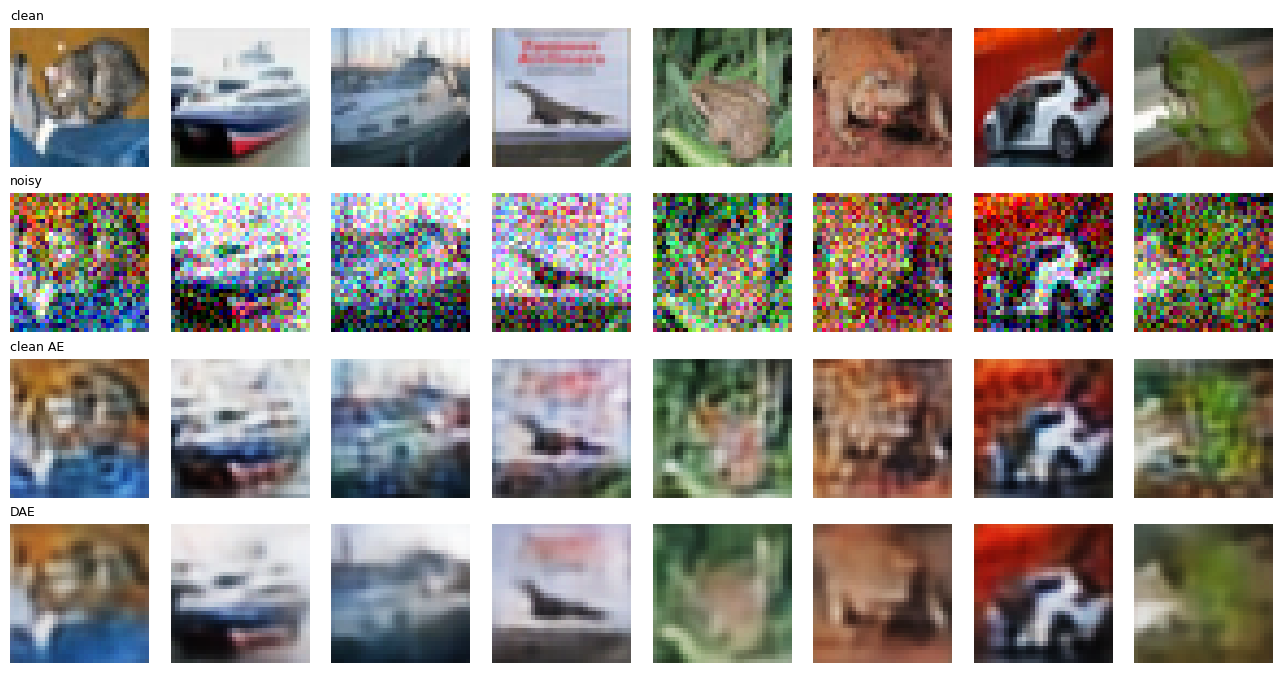

In [14]:
# ---------- Q3(b): denoising autoencoder ----------
def add_noise(x, gen=None):
    noise = torch.randn(x.shape, device=x.device, generator=gen) * NOISE_SIGMA
    return (x + noise).clamp(0, 1)

gen = torch.Generator(device=device).manual_seed(SEED)
x_val_noisy = add_noise(X["val"], gen)       # fixed noisy copies of val and test
x_test_noisy = add_noise(X["test"], gen)

set_seed()
dae = ConvAE(d_sel).to(device)
log("--- training DENOISING AE (d = %d), gaussian noise sigma = %.2f, no labels" % (d_sel, NOISE_SIGMA))
dae_hist = train_ae(dae, X["train"], X["val"], EPOCHS_AE, corrupt=add_noise, xva_in=x_val_noisy, tag="DAE")
torch.save(dae.state_dict(), "checkpoints/Q3b_DAE.pt")

inputs = {"clean test images (reference)": X["test"],
          "corrupted test images": x_test_noisy,
          "clean-AE reconstruction of corrupted": recon(ae_sel, x_test_noisy),
          "DAE reconstruction of corrupted": recon(dae, x_test_noisy),
          "clean-AE reconstruction of clean (AE information loss only)": recon(ae_sel, X["test"]),
          "DAE reconstruction of clean": recon(dae, X["test"])}
rows = []
for name, xin in inputs.items():
    rows.append({"classifier input": name, "cnn_test_acc": round(accuracy_of(cnn_main, xin, Y["test"]), 4),
                 "mse_vs_clean": round(F.mse_loss(xin, X["test"]).item(), 6)})
q3b = pd.DataFrame(rows)
add_summary("Q3(b) fixed CNN (from Q1a) on corrupted images and on reconstructions", q3b)

acc_clean, acc_corrupt = rows[0]["cnn_test_acc"], rows[1]["cnn_test_acc"]
acc_cleanAE, acc_dae = rows[2]["cnn_test_acc"], rows[3]["cnn_test_acc"]
recovered = (acc_dae - acc_corrupt) / max(acc_clean - acc_corrupt, 1e-9)
log("Corruption costs the classifier %.2f points. The DAE recovers %.0f%% of that loss (clean AE: %.0f%%)." %
    (100 * (acc_clean - acc_corrupt), 100 * recovered, 100 * (acc_cleanAE - acc_corrupt) / max(acc_clean - acc_corrupt, 1e-9)))
log("Remaining gap to clean-image accuracy after denoising: %.2f points." % (100 * (acc_clean - acc_dae)))
RESULTS["Q3b"] = {"sigma": NOISE_SIGMA, "d": d_sel, "table": rows, "recovered_fraction": recovered,
                  "dae_best_epoch": dae_hist["best_epoch"], "dae_best_val_mse": dae_hist["best_val_mse"]}
save_results()

fig, axs = plt.subplots(4, 8, figsize=(13, 6.8))
for j in range(8):
    for r, (title, t) in enumerate([("clean", X["test"]), ("noisy", x_test_noisy), ("clean AE", inputs["clean-AE reconstruction of corrupted"]),
                                    ("DAE", inputs["DAE reconstruction of corrupted"])]):
        axs[r, j].imshow(img_np(t[j])); axs[r, j].axis("off")
        if j == 0:
            axs[r, j].set_title(title, loc="left", fontsize=9)
save_show("q3b_denoising_examples")

**(c)** Class information in the learned representations, **without fine-tuning any encoder**: a linear probe (one linear layer, trained on frozen standardised bottleneck features; weight decay chosen on validation, test accuracy reported once). Controls: raw pixels, and an untrained (random-weight) encoder with the same architecture.
We then compare class information with reconstruction quality across the models.

  probe done: clean AE d=32 {'train_acc': 0.3644, 'val_acc': 0.3566, 'test_acc': 0.3609, 'weight_decay': 0.0}
  probe done: clean AE d=128 {'train_acc': 0.4024, 'val_acc': 0.3934, 'test_acc': 0.3934, 'weight_decay': 0.001}
  probe done: clean AE d=512 {'train_acc': 0.4649, 'val_acc': 0.4502, 'test_acc': 0.4442, 'weight_decay': 0.0}
  probe done: denoising AE d=512 {'train_acc': 0.5112, 'val_acc': 0.483, 'test_acc': 0.4947, 'weight_decay': 0.0}
  probe done: random untrained encoder d=512 {'train_acc': 0.4596, 'val_acc': 0.434, 'test_acc': 0.431, 'weight_decay': 0.0}
=== Q3(c) reconstruction quality vs class information (linear probe) ===
                representation  dim  encoder_params  test_recon_mse  train_acc  val_acc  test_acc  weight_decay
                 clean AE d=32   32          231168        0.011504     0.3644   0.3566    0.3609         0.000
                clean AE d=128  128          427872        0.004829     0.4024   0.3934    0.3934         0.001
                cl

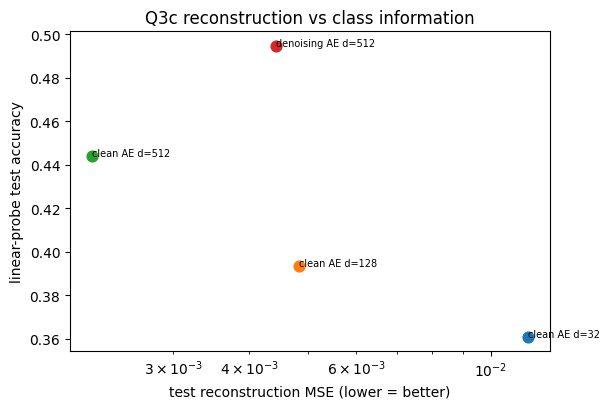

In [15]:
# ---------- Q3(c): linear probes on frozen representations ----------
@torch.no_grad()
def get_latents(ae, x, bs=1000):
    ae.eval()
    return torch.cat([ae.encode(x[i:i + bs]) for i in range(0, len(x), bs)])

def linear_probe(ztr, zva, zte, wds=(0.0, 1e-4, 1e-3, 1e-2)):
    mu, sd = ztr.mean(0, keepdim=True), ztr.std(0, keepdim=True) + 1e-6
    ztr, zva, zte = (ztr - mu) / sd, (zva - mu) / sd, (zte - mu) / sd
    best = None
    for wd in wds:
        set_seed()
        lin = nn.Linear(ztr.shape[1], 10).to(device)
        opt = torch.optim.Adam(lin.parameters(), lr=1e-2, weight_decay=wd)
        for ep in range(PROBE_EPOCHS):
            for zb, yb in batches(ztr, Y["train"], 512, True):
                loss = F.cross_entropy(lin(zb), yb)
                opt.zero_grad(set_to_none=True)
                loss.backward()
                opt.step()
        with torch.no_grad():
            va = (lin(zva).argmax(1) == Y["val"]).float().mean().item()
        if best is None or va > best[0]:
            best = (va, wd, lin)
    va, wd, lin = best
    with torch.no_grad():
        tr = (lin(ztr).argmax(1) == Y["train"]).float().mean().item()
        te = (lin(zte).argmax(1) == Y["test"]).float().mean().item()
    return {"train_acc": round(tr, 4), "val_acc": round(va, 4), "test_acc": round(te, 4), "weight_decay": wd}

set_seed()
random_ae = ConvAE(d_sel).to(device)         # untrained, random weights (baseline)

reps = {}
for d in BOTTLENECKS:
    reps["clean AE d=%d" % d] = (clean_aes[d], d)
reps["denoising AE d=%d" % d_sel] = (dae, d_sel)
reps["random untrained encoder d=%d" % d_sel] = (random_ae, d_sel)

rows = []
for name, (ae, d) in reps.items():
    res = linear_probe(get_latents(ae, X["train"]), get_latents(ae, X["val"]), get_latents(ae, X["test"]))
    is_random = name.startswith("random")
    rows.append({"representation": name, "dim": d, "encoder_params": count_params(ae.enc_conv) + count_params(ae.enc_fc),
                 "test_recon_mse": None if is_random else round(recon_mse(ae, X["test"]), 6), **res})
    log("  probe done:", name, res)
res = linear_probe(X["train"].flatten(1), X["val"].flatten(1), X["test"].flatten(1))
rows.append({"representation": "raw pixels (3072)", "dim": 3072, "encoder_params": 0, "test_recon_mse": 0.0, **res})
q3c = pd.DataFrame(rows)
add_summary("Q3(c) reconstruction quality vs class information (linear probe)", q3c)
q3c.to_csv("results/q3c_table.csv", index=False)
RESULTS["Q3c"] = rows

# do reconstruction quality and class information agree?
clean_rows = [r for r in rows if r["representation"].startswith("clean AE")]
by_mse = [r["representation"] for r in sorted(clean_rows, key=lambda r: r["test_recon_mse"])]
by_probe = [r["representation"] for r in sorted(clean_rows, key=lambda r: -r["test_acc"])]
log("Ranking by reconstruction (best first):", by_mse)
log("Ranking by class information (best first):", by_probe)
log("Rankings agree." if by_mse == by_probe else "Rankings DISAGREE - reconstruction quality is not a reliable proxy for class information.")
for a, b in zip(clean_rows[:-1], clean_rows[1:]):
    log("  %s -> %s: reconstruction MSE x%.2f, probe test acc %+.2f points" % (a["representation"], b["representation"], b["test_recon_mse"] / a["test_recon_mse"], 100 * (b["test_acc"] - a["test_acc"])))
dae_row = [r for r in rows if r["representation"].startswith("denoising")][0]
sel_row = [r for r in clean_rows if r["representation"] == "clean AE d=%d" % d_sel][0]
log("Denoising AE vs clean AE at the same d: recon MSE (clean test) %.6f vs %.6f | probe test acc %.4f vs %.4f" %
    (dae_row["test_recon_mse"], sel_row["test_recon_mse"], dae_row["test_acc"], sel_row["test_acc"]))

# representation fixed for Q4: the clean AE with the best VALIDATION probe accuracy (chosen with validation only)
rep_d = max(BOTTLENECKS, key=lambda d: [r for r in clean_rows if r["representation"] == "clean AE d=%d" % d][0]["val_acc"])
log("Representation fixed for Q4: clean AE bottleneck, d = %d (best validation probe accuracy among clean AEs)" % rep_d)
RESULTS["Q4_representation"] = {"clean_ae_d": rep_d}
save_results()

fig, ax = plt.subplots(figsize=(6.2, 4.2))
for r in rows:
    if r["test_recon_mse"] not in (None, 0.0):
        ax.scatter(r["test_recon_mse"], r["test_acc"], s=60)
        ax.annotate(r["representation"], (r["test_recon_mse"], r["test_acc"]), fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("test reconstruction MSE (lower = better)"); ax.set_ylabel("linear-probe test accuracy")
ax.set_title("Q3c reconstruction vs class information")
save_show("q3c_recon_vs_probe")

## Q4 (Bonus) – SVMs and clustering on one fixed representation
**Fixed representation:** the bottleneck features of the clean autoencoder from Q3 (the one with the best *validation* linear-probe accuracy), standardised with train statistics. It is label-free, so the clustering part is clean as well.
**Subset note:** a fixed stratified **6,000-image training subset** is used for *all* SVM fits (chosen before any model selection, with the seed). Clustering uses all 45,000 training representations. Validation (5,000) and test (10,000) sets are complete.

In [16]:
# ---------- Q4(a) setup: fixed representation + sweep ----------
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

rep_ae = clean_aes[rep_d]
Ztr_full = get_latents(rep_ae, X["train"]).cpu().numpy()
Zva = get_latents(rep_ae, X["val"]).cpu().numpy()
Zte = get_latents(rep_ae, X["test"]).cpu().numpy()
scaler = StandardScaler().fit(Ztr_full)
Ztr_full, Zva, Zte = scaler.transform(Ztr_full), scaler.transform(Zva), scaler.transform(Zte)
np.savez("results/q4_representation_stats.npz", mean=scaler.mean_, scale=scaler.scale_)

# fixed stratified subset for the SVMs (chosen BEFORE model selection)
svm_idx, _ = train_test_split(np.arange(len(y_train)), train_size=SVM_SUBSET, stratify=y_train, random_state=SEED)
np.save("results/q4_svm_subset_idx.npy", svm_idx)
Zs, ys = Ztr_full[svm_idx], y_train[svm_idx]
log("Q4 representation dim = %d | SVM training subset = %d images (%s per class)" % (Zs.shape[1], len(ys), np.bincount(ys).tolist()))

KERNELS = {"linear": dict(kernel="linear"), "poly3": dict(kernel="poly", degree=3, gamma="scale"), "rbf": dict(kernel="rbf", gamma="scale")}
fitted, rows = {}, []
for kname, kw in KERNELS.items():
    for C in C_LIST:
        t0 = time.time()
        clf = SVC(C=C, cache_size=2000, max_iter=SVM_MAX_ITER, **kw).fit(Zs, ys)
        n_it = getattr(clf, "n_iter_", None)
        converged = True if n_it is None else bool((np.asarray(n_it) < SVM_MAX_ITER).all())
        rows.append({"kernel": kname, "C": C, "train_acc": round(clf.score(Zs, ys), 4), "val_acc": round(clf.score(Zva, y_val), 4),
                     "sv_frac": round(clf.n_support_.sum() / len(ys), 4), "converged": converged, "fit_seconds": round(time.time() - t0, 1)})
        fitted[(kname, C)] = clf
        log("  ", rows[-1])
sweep = pd.DataFrame(rows)
sweep.to_csv("results/q4a_sweep.csv", index=False)
add_summary("Q4(a) complete C and kernel sweep (selection uses validation only)", sweep)

Q4 representation dim = 512 | SVM training subset = 6000 images ([600, 600, 600, 600, 600, 600, 600, 600, 600, 600] per class)
   {'kernel': 'linear', 'C': 0.01, 'train_acc': 0.632, 'val_acc': 0.3956, 'sv_frac': np.float64(0.8992), 'converged': True, 'fit_seconds': 18.5}
   {'kernel': 'linear', 'C': 0.1, 'train_acc': 0.743, 'val_acc': 0.365, 'sv_frac': np.float64(0.862), 'converged': True, 'fit_seconds': 26.6}
   {'kernel': 'linear', 'C': 1, 'train_acc': 0.8498, 'val_acc': 0.3554, 'sv_frac': np.float64(0.8465), 'converged': False, 'fit_seconds': 42.8}
   {'kernel': 'linear', 'C': 10, 'train_acc': 0.883, 'val_acc': 0.3466, 'sv_frac': np.float64(0.9075), 'converged': False, 'fit_seconds': 51.7}
   {'kernel': 'linear', 'C': 100, 'train_acc': 0.8142, 'val_acc': 0.3402, 'sv_frac': np.float64(0.9223), 'converged': False, 'fit_seconds': 52.4}
   {'kernel': 'poly3', 'C': 0.01, 'train_acc': 0.2998, 'val_acc': 0.19, 'sv_frac': np.float64(1.0), 'converged': True, 'fit_seconds': 25.8}
   {'kernel'

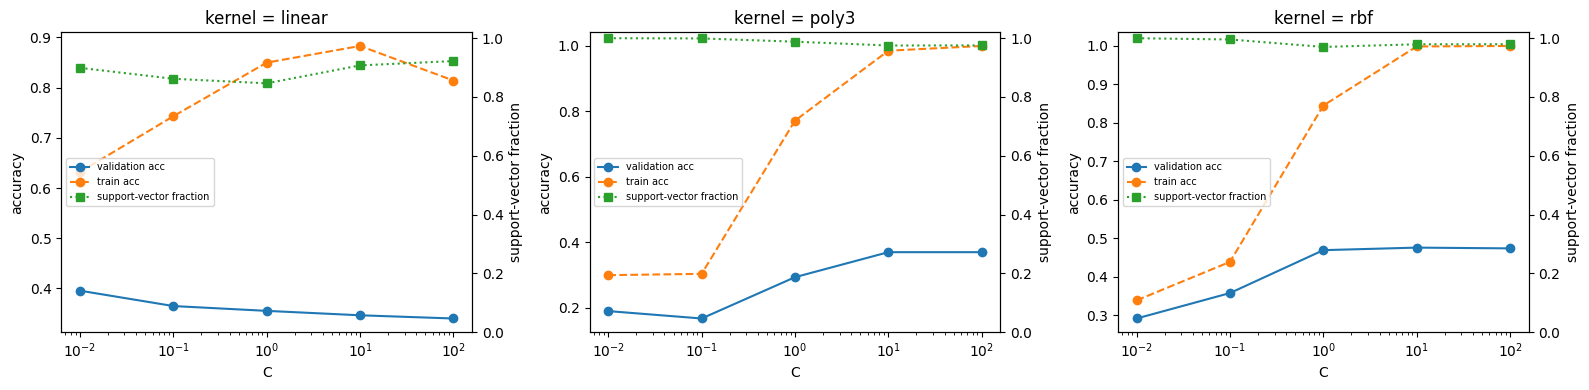

SELECTED by validation only: kernel = rbf, C = 10.0 (val acc 0.4754, train acc 0.9987, SV fraction 0.979)
FINAL TEST ACCURACY of the selected SVM: 0.4720
  linear | smallest C: train 0.632 val 0.396 SV 0.90 | largest C: train 0.814 val 0.340 SV 0.92 | max train-val gap 0.536
  poly3  | smallest C: train 0.300 val 0.190 SV 1.00 | largest C: train 1.000 val 0.370 SV 0.98 | max train-val gap 0.630
  rbf    | smallest C: train 0.338 val 0.291 SV 1.00 | largest C: train 1.000 val 0.473 SV 0.98 | max train-val gap 0.527


In [17]:
# ---------- Q4(a): plots, selection on validation, ONE test evaluation ----------
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, kname in zip(axs, KERNELS):
    d = sweep[sweep["kernel"] == kname]
    l1, = ax.plot(d["C"], d["val_acc"], "-o", label="validation acc")
    l2, = ax.plot(d["C"], d["train_acc"], "--o", label="train acc")
    ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("accuracy"); ax.set_title("kernel = " + kname)
    ax2 = ax.twinx()
    l3, = ax2.plot(d["C"], d["sv_frac"], ":s", color="tab:green", label="support-vector fraction")
    ax2.set_ylabel("support-vector fraction"); ax2.set_ylim(0, 1.02)
    ax.legend(handles=[l1, l2, l3], fontsize=7, loc="center left")
save_show("q4a_C_sweep")

best = sweep.sort_values(["val_acc", "sv_frac"], ascending=[False, True]).iloc[0]
best_key = (best["kernel"], best["C"])
final_svm = fitted[best_key]
log("SELECTED by validation only: kernel = %s, C = %s (val acc %.4f, train acc %.4f, SV fraction %.3f)" %
    (best["kernel"], best["C"], best["val_acc"], best["train_acc"], best["sv_frac"]))
pred_te = final_svm.predict(Zte)                     # the ONLY test-set evaluation of any SVM
svm_test_acc = float((pred_te == y_test).mean())
log("FINAL TEST ACCURACY of the selected SVM: %.4f" % svm_test_acc)

for kname in KERNELS:
    d = sweep[sweep["kernel"] == kname]
    lo, hi = d.iloc[0], d.iloc[-1]
    log("  %-6s | smallest C: train %.3f val %.3f SV %.2f | largest C: train %.3f val %.3f SV %.2f | max train-val gap %.3f" %
        (kname, lo["train_acc"], lo["val_acc"], lo["sv_frac"], hi["train_acc"], hi["val_acc"], hi["sv_frac"], (d["train_acc"] - d["val_acc"]).max()))
RESULTS["Q4a"] = {"selected_kernel": best["kernel"], "selected_C": best["C"], "val_acc": best["val_acc"],
                  "sv_frac": best["sv_frac"], "test_acc": svm_test_acc, "subset": SVM_SUBSET}
save_results()

Three most confused class pairs on the test set: [('cat', 'dog', np.float64(0.208)), ('automobile', 'truck', np.float64(0.18)), ('bird', 'deer', np.float64(0.152))]


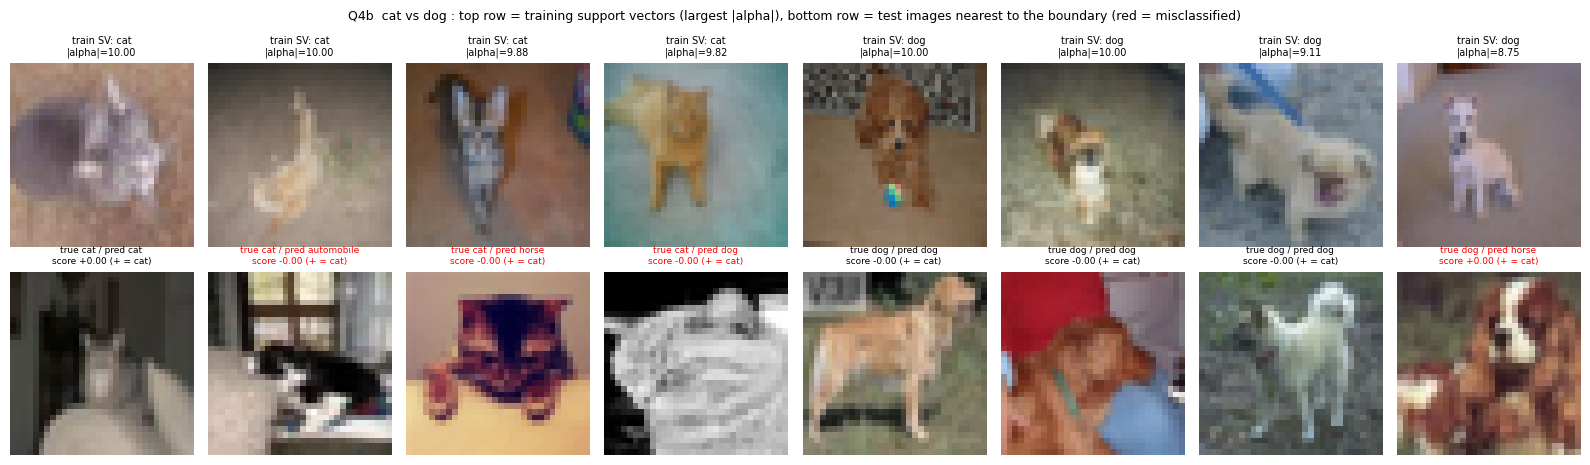

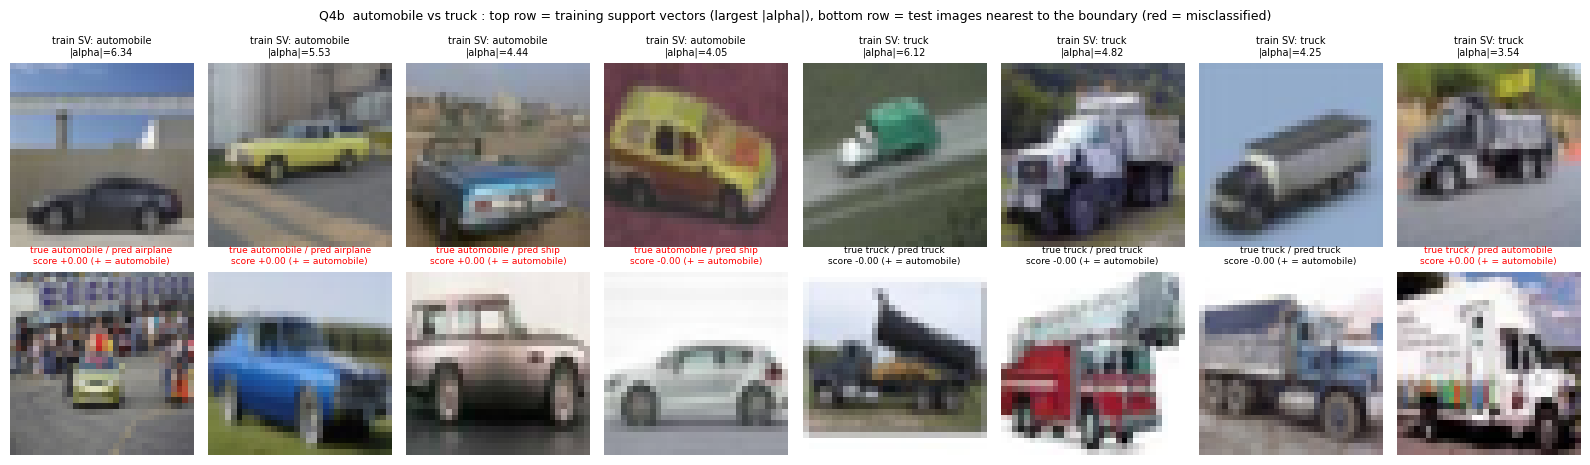

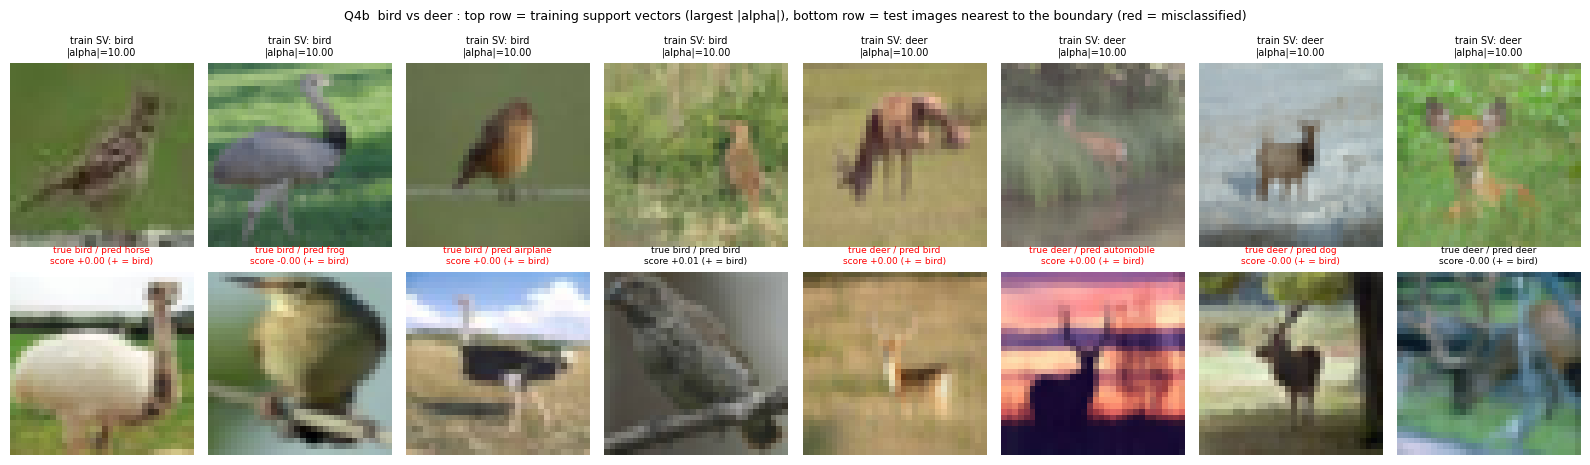

=== Q4(b) difficult pairs: SVM scores, support vectors and geometry ===
               pair  multiclass_confusion_rate  errors_a_to_b  errors_b_to_a  binary_pair_error_rate  mean_abs_score_correct  mean_abs_score_wrong  pair_support_vectors  bounded_sv_fraction  centroid_dist_over_radius  errors_nearer_other_centroid
         cat vs dog                      0.208            187            229                   0.380                   0.416                 0.325                  1166                0.003                      0.098                         0.584
automobile vs truck                      0.180            167            192                   0.252                   0.490                 0.281                  1120                0.000                      0.163                         0.705
       bird vs deer                      0.152            132            171                   0.339                   0.616                 0.413                  1033                0.0

In [18]:
# ---------- Q4(b): difficult class pairs ----------
from scipy.stats import spearmanr

cm = confusion_matrix(y_test, pred_te, labels=list(range(10)))
pair_list = [(a, b) for a in range(10) for b in range(a + 1, 10)]
pair_rate = {p: (cm[p[0], p[1]] + cm[p[1], p[0]]) / (cm[p[0]].sum() + cm[p[1]].sum()) for p in pair_list}
hard_pairs = sorted(pair_list, key=lambda p: pair_rate[p], reverse=True)[:3]
log("Three most confused class pairs on the test set:", [(class_names[a], class_names[b], round(pair_rate[(a, b)], 3)) for a, b in hard_pairs])

# one-vs-one decision scores (column order is (0,1),(0,2),...,(8,9)); positive = first class of the pair
final_svm.decision_function_shape = "ovo"
S_te = final_svm.decision_function(Zte)
pair_col = {p: i for i, p in enumerate(pair_list)}
C_sel = float(best["C"])

# geometry of the representation (train statistics): class centroids and spread
mu = np.stack([Ztr_full[y_train == c].mean(0) for c in range(10)])
rad = np.array([np.linalg.norm(Ztr_full[y_train == c] - mu[c], axis=1).mean() for c in range(10)])
def centroid_ratio(a, b):
    return np.linalg.norm(mu[a] - mu[b]) / ((rad[a] + rad[b]) / 2)

starts = np.concatenate([[0], np.cumsum(final_svm.n_support_)])
def pair_svs(a, b):          # support vectors actually used by the (a vs b) binary problem (a < b)
    sv_a, sv_b = np.arange(starts[a], starts[a + 1]), np.arange(starts[b], starts[b + 1])
    return sv_a, np.abs(final_svm.dual_coef_[b - 1, sv_a]), sv_b, np.abs(final_svm.dual_coef_[a, sv_b])

pair_rows = []
for (a, b) in hard_pairs:
    s = S_te[:, pair_col[(a, b)]]
    in_pair = np.where((y_test == a) | (y_test == b))[0]
    if s[y_test == a].mean() < s[y_test == b].mean():       # make positive = class a (safety)
        s = -s
    wrong_pair = ((s[in_pair] > 0) != (y_test[in_pair] == a))
    sv_a, coef_a, sv_b, coef_b = pair_svs(a, b)
    coefs = np.concatenate([coef_a, coef_b]); used = coefs > 1e-8
    # confusions a->b and b->a: are they nearer to the other class centroid?
    err_idx = np.where(((y_test == a) & (pred_te == b)) | ((y_test == b) & (pred_te == a)))[0]
    if len(err_idx):
        d_own = np.array([np.linalg.norm(Zte[i] - mu[y_test[i]]) for i in err_idx])
        d_other = np.array([np.linalg.norm(Zte[i] - mu[b if y_test[i] == a else a]) for i in err_idx])
        frac_closer = float((d_other < d_own).mean())
    else:
        frac_closer = float("nan")
    pair_rows.append({"pair": class_names[a] + " vs " + class_names[b], "multiclass_confusion_rate": round(pair_rate[(a, b)], 3),
                      "errors_a_to_b": int(cm[a, b]), "errors_b_to_a": int(cm[b, a]),
                      "binary_pair_error_rate": round(float(wrong_pair.mean()), 3),
                      "mean_abs_score_correct": round(float(np.abs(s[in_pair][~wrong_pair]).mean()), 3),
                      "mean_abs_score_wrong": round(float(np.abs(s[in_pair][wrong_pair]).mean()), 3) if wrong_pair.any() else None,
                      "pair_support_vectors": int(used.sum()), "bounded_sv_fraction": round(float((coefs[used] >= C_sel - 1e-6).mean()), 3),
                      "centroid_dist_over_radius": round(float(centroid_ratio(a, b)), 3),
                      "errors_nearer_other_centroid": round(frac_closer, 3)})

    # figure: training support vectors (top) and test images nearest to the boundary (bottom)
    fig, axs = plt.subplots(2, 8, figsize=(16, 4.8))
    sv_show = []
    for cls, svs, cf in [(a, sv_a, coef_a), (b, sv_b, coef_b)]:
        order = np.argsort(-cf)[:4]
        sv_show += [(cls, int(svs[o]), float(cf[o])) for o in order]
    for j, (cls, sv, cf) in enumerate(sv_show):
        axs[0, j].imshow(x_train[svm_idx[final_svm.support_[sv]]]); axs[0, j].axis("off")
        axs[0, j].set_title("train SV: %s\n|alpha|=%.2f" % (class_names[cls], cf), fontsize=7)
    near = []
    for cls in (a, b):
        idx_c = np.where(y_test == cls)[0]
        near += list(idx_c[np.argsort(np.abs(s[idx_c]))[:4]])
    for j, i in enumerate(near):
        axs[1, j].imshow(x_test[i]); axs[1, j].axis("off")
        bad = pred_te[i] != y_test[i]
        axs[1, j].set_title("true %s / pred %s\nscore %+.2f (+ = %s)" % (class_names[y_test[i]], class_names[pred_te[i]], s[i], class_names[a]),
                            fontsize=6.5, color="red" if bad else "black")
    fig.suptitle("Q4b  %s vs %s : top row = training support vectors (largest |alpha|), bottom row = test images nearest to the boundary (red = misclassified)" % (class_names[a], class_names[b]), fontsize=9)
    save_show("q4b_pair_%s_vs_%s" % (class_names[a], class_names[b]))

q4b = pd.DataFrame(pair_rows)
add_summary("Q4(b) difficult pairs: SVM scores, support vectors and geometry", q4b)

# geometry vs errors over ALL 45 pairs
ratios = [centroid_ratio(a, b) for a, b in pair_list]
rates = [pair_rate[p] for p in pair_list]
rho, pval = spearmanr(ratios, rates)
log("Over all 45 pairs: Spearman correlation between (centroid distance / class spread) and test confusion rate = %.3f (p = %.3g)" % (rho, pval))
log("Median centroid-distance/spread over all pairs = %.3f" % float(np.median(ratios)))
RESULTS["Q4b"] = {"pairs": pair_rows, "spearman_ratio_vs_confusion": float(rho), "spearman_p": float(pval)}
save_results()

   {'method': 'kmeans', 'k': 5, 'train_silhouette': np.float32(0.0009), 'val_silhouette': np.float32(0.0027), 'val_davies_bouldin': np.float64(4.5), 'seconds': 10.1}
   {'method': 'kmeans', 'k': 8, 'train_silhouette': np.float32(-0.0011), 'val_silhouette': np.float32(0.0), 'val_davies_bouldin': np.float64(4.462), 'seconds': 22.3}
   {'method': 'kmeans', 'k': 10, 'train_silhouette': np.float32(-0.0068), 'val_silhouette': np.float32(-0.0038), 'val_davies_bouldin': np.float64(4.306), 'seconds': 14.0}
   {'method': 'kmeans', 'k': 12, 'train_silhouette': np.float32(-0.0096), 'val_silhouette': np.float32(-0.0039), 'val_davies_bouldin': np.float64(4.312), 'seconds': 12.6}
   {'method': 'kmeans', 'k': 15, 'train_silhouette': np.float32(-0.0268), 'val_silhouette': np.float32(-0.0254), 'val_davies_bouldin': np.float64(4.345), 'seconds': 17.4}
   {'method': 'kmeans', 'k': 20, 'train_silhouette': np.float32(-0.0375), 'val_silhouette': np.float32(-0.0375), 'val_davies_bouldin': np.float64(4.323), '

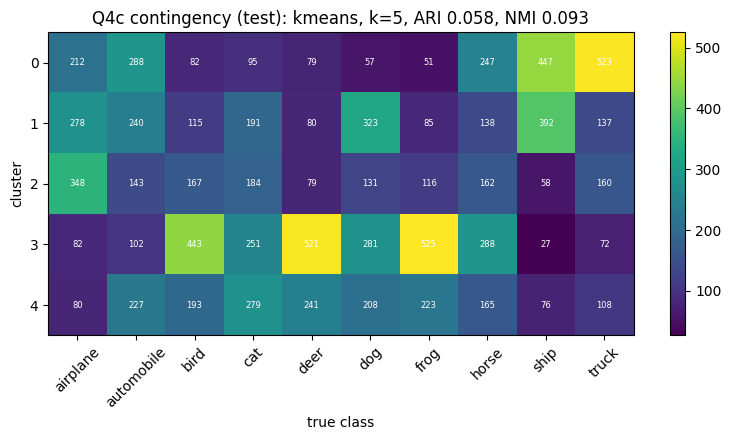

=== Q4(c) per-class SVM recall vs cluster-majority recall ===
     class  svm_recall  cluster_majority_recall  svm_minus_cluster
  airplane       0.541                    0.348              0.193
automobile       0.608                    0.000              0.608
      bird       0.341                    0.000              0.341
       cat       0.337                    0.279              0.058
      deer       0.354                    0.000              0.354
       dog       0.377                    0.000              0.377
      frog       0.503                    0.525             -0.022
     horse       0.510                    0.000              0.510
      ship       0.596                    0.392              0.204
     truck       0.553                    0.523              0.030

Spearman correlation over all 45 pairs between SVM confusion rate and cluster overlap = 0.762 (p = 1.22e-09)
=== Q4(c) pairs the clustering merges but the SVM separates ===
               pair  svm_co

In [19]:
# ---------- Q4(c): clustering (labels never used for fitting or selection) ----------
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, davies_bouldin_score

rs = np.random.RandomState(SEED).choice(len(Ztr_full), min(5000, len(Ztr_full)), replace=False)    # label-free train sample for silhouette
cl_models, rows = {}, []
for method in ["kmeans", "gmm_diag"]:
    for k in K_LIST:
        t0 = time.time()
        if method == "kmeans":
            model = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(Ztr_full)
        else:
            model = GaussianMixture(n_components=k, covariance_type="diag", max_iter=100, random_state=SEED).fit(Ztr_full)
        lab_val, lab_tr = model.predict(Zva), model.predict(Ztr_full[rs])
        rows.append({"method": method, "k": k,
                     "train_silhouette": round(silhouette_score(Ztr_full[rs], lab_tr), 4),
                     "val_silhouette": round(silhouette_score(Zva, lab_val), 4),
                     "val_davies_bouldin": round(davies_bouldin_score(Zva, lab_val), 3),
                     "seconds": round(time.time() - t0, 1)})
        cl_models[(method, k)] = model
        log("  ", rows[-1])
cl_sel = pd.DataFrame(rows)
add_summary("Q4(c) clustering model selection (label-free: validation silhouette)", cl_sel)
cl_sel.to_csv("results/q4c_selection.csv", index=False)

best_cl = cl_sel.sort_values("val_silhouette", ascending=False).iloc[0]
cl_key = (best_cl["method"], int(best_cl["k"]))
cl_final = cl_models[cl_key]
K_SEL = cl_key[1]
log("SELECTED clustering (validation silhouette only): %s with k = %d" % cl_key)

# assign test representations; test labels are used ONLY now, for evaluation
test_clusters = cl_final.predict(Zte)
ari = adjusted_rand_score(y_test, test_clusters)
nmi = normalized_mutual_info_score(y_test, test_clusters)
log("TEST ARI = %.4f | TEST NMI = %.4f" % (ari, nmi))
ref = {}
if ("kmeans", 10) in cl_models:       # reference only (not used for selection)
    t10 = cl_models[("kmeans", 10)].predict(Zte)
    ref = {"kmeans_k10_ARI": adjusted_rand_score(y_test, t10), "kmeans_k10_NMI": normalized_mutual_info_score(y_test, t10)}
    log("Reference (not used for selection): KMeans k=10 -> ARI %.4f, NMI %.4f" % (ref["kmeans_k10_ARI"], ref["kmeans_k10_NMI"]))

cont = pd.crosstab(pd.Series(test_clusters, name="cluster"), pd.Series(y_test, name="class"))
cont = cont.reindex(columns=range(10), fill_value=0)
cont.columns = class_names
cont.to_csv("results/q4c_contingency.csv")
add_summary("Q4(c) test cluster-to-class contingency table (rows = clusters)", cont.reset_index())

fig, ax = plt.subplots(figsize=(8, 0.4 * K_SEL + 2.5))
im = ax.imshow(cont.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(10)); ax.set_xticklabels(class_names, rotation=45); ax.set_yticks(range(len(cont))); ax.set_yticklabels(cont.index)
ax.set_xlabel("true class"); ax.set_ylabel("cluster"); ax.set_title("Q4c contingency (test): %s, k=%d, ARI %.3f, NMI %.3f" % (cl_key[0], K_SEL, ari, nmi))
for i in range(cont.shape[0]):
    for j in range(10):
        ax.text(j, i, int(cont.values[i, j]), ha="center", va="center", color="white", fontsize=6)
fig.colorbar(im)
save_show("q4c_contingency")

# ---- classification vs clustering disagreement ----
maj = cont.values.argmax(1)                              # majority class of each cluster (evaluation only)
clu_pred_class = maj[np.searchsorted(cont.index.values, test_clusters)]
cluster_recall = [float((clu_pred_class[y_test == c] == c).mean()) for c in range(10)]
svm_recall = [float((pred_te[y_test == c] == c).mean()) for c in range(10)]
class_cmp = pd.DataFrame({"class": class_names, "svm_recall": np.round(svm_recall, 3), "cluster_majority_recall": np.round(cluster_recall, 3)})
class_cmp["svm_minus_cluster"] = (class_cmp["svm_recall"] - class_cmp["cluster_majority_recall"]).round(3)
add_summary("Q4(c) per-class SVM recall vs cluster-majority recall", class_cmp)

P = cont.values.T / np.maximum(cont.values.T.sum(1, keepdims=True), 1)        # class -> distribution over clusters
def cluster_cos(a, b):
    return float(P[a] @ P[b] / (np.linalg.norm(P[a]) * np.linalg.norm(P[b]) + 1e-12))
dis = pd.DataFrame({"pair": [class_names[a] + " vs " + class_names[b] for a, b in pair_list],
                    "svm_confusion_rate": [round(pair_rate[p], 3) for p in pair_list],
                    "cluster_overlap_cosine": [round(cluster_cos(a, b), 3) for a, b in pair_list]})
dis["gap_clusterRank_minus_svmRank"] = (dis["cluster_overlap_cosine"].rank(pct=True) - dis["svm_confusion_rate"].rank(pct=True)).round(3)
rho_cs, p_cs = spearmanr(dis["svm_confusion_rate"], dis["cluster_overlap_cosine"])
log("Spearman correlation over all 45 pairs between SVM confusion rate and cluster overlap = %.3f (p = %.3g)" % (rho_cs, p_cs))
top_merge = dis.sort_values("gap_clusterRank_minus_svmRank", ascending=False).head(3)
top_split = dis.sort_values("gap_clusterRank_minus_svmRank").head(3)
add_summary("Q4(c) pairs the clustering merges but the SVM separates", top_merge)
add_summary("Q4(c) pairs the SVM confuses but the clustering separates", top_split)
dis.to_csv("results/q4c_pair_disagreement.csv", index=False)
RESULTS["Q4c"] = {"method": cl_key[0], "k": K_SEL, "test_ARI": ari, "test_NMI": nmi, **ref,
                  "spearman_svm_vs_cluster": float(rho_cs), "top_merge": top_merge.to_dict(orient="records"),
                  "top_split": top_split.to_dict(orient="records"), "svm_test_acc": svm_test_acc,
                  "per_class": class_cmp.to_dict(orient="records")}
save_results()

## Wrap-up – collect everything for the report and the GitHub repo

In [20]:
# ---------- collect all numbers + write repo files ----------
import platform
save_results()
with open("results/results_summary.txt", "w") as f:
    f.write("ML Assignment 3 - roll %s - seed %d\n\n" % (ROLL_NO, SEED))
    f.write("\n".join(SUMMARY))
print(open("results/results_summary.txt").read())

reqs = ["torch==" + torch.__version__.split("+")[0], "torchvision==" + torchvision.__version__.split("+")[0],
        "numpy==" + np.__version__, "scikit-learn==" + sklearn.__version__, "pandas==" + pd.__version__,
        "matplotlib==" + plt.matplotlib.__version__, "scipy==" + __import__("scipy").__version__]
open("requirements.txt", "w").write("\n".join(reqs) + "\n")

readme = """# ML Assignment 3 - MLPs, CNNs, Autoencoders, SVMs and Clustering on CIFAR10
Name / roll no: %s (seed = %d, the numeric part of the roll number)

## Reproduce
    pip install -r requirements.txt
    jupyter nbconvert --to notebook --execute ML_Assignment3.ipynb --output ML_Assignment3_executed.ipynb
    # or, as a plain script:
    python ML_Assignment3.py

Everything runs top to bottom (about 1-1.5 h on a Colab T4). Outputs: figures/, results/ (tables, json, saved split), logs/run_log.txt, checkpoints/.
Saved split: results/split_seed%d.npz. Fixed pixel permutation (Q2b): results/pixel_permutation.npy. SVM subset (Q4): results/q4_svm_subset_idx.npy.
Python %s
""" % (ROLL_NO, SEED, SEED, platform.python_version())
open("README.md", "w").write(readme)
log("Wrote results/results_summary.txt, requirements.txt, README.md")
log("Done. Download these folders/files: figures/, results/, logs/, requirements.txt, README.md, ML_Assignment3.ipynb")

ML Assignment 3 - roll M26CSA008 - seed 26008

=== Q1(a) comparison table (train/val at best-val epoch, test = final) ===
                model  params  best_epoch  train_acc  val_acc  test_acc  train_val_gap
            MLP-small  856074          10     0.7747   0.5622    0.5524         0.2125
  CNN (param-matched)  854094          22     1.0000   0.8780    0.8716         0.1220
MLP-large (4x params) 3414538          25     0.9998   0.5748    0.5657         0.4250

=== Q1(b) memorisation summary ===
 p_random_labels  params  peak_val_acc  peak_val_epoch  final_val_acc  memorisation_start_epoch  epoch_train_acc_99  final_train_acc  final_test_acc
             0.0 4206602        0.4838              55         0.4770                       NaN                  18           1.0000          0.4836
             0.5 4206602        0.3610               5         0.2972                       6.0                  24           0.9998          0.2982
             1.0 4206602        0.1392         

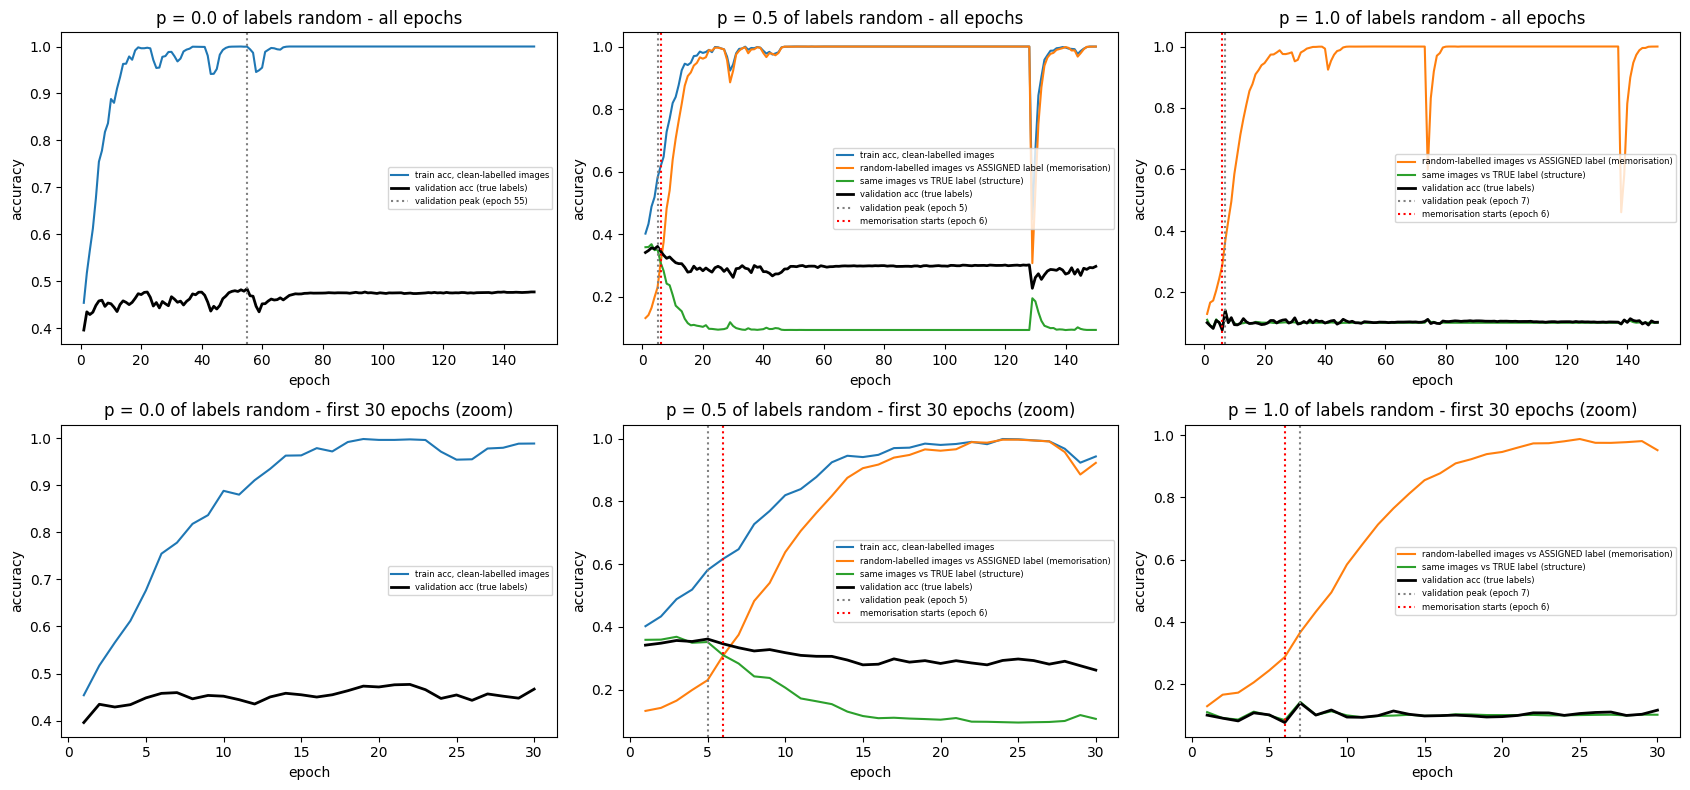

p=0.5: accuracy on random-labelled images w.r.t. their TRUE label peaks at 0.368 in epoch 3; memorisation overtakes it in epoch 7; validation peaks at 0.361 in epoch 5 and ends at 0.297.
p=1.0: accuracy on random-labelled images w.r.t. their TRUE label peaks at 0.143 in epoch 7; memorisation overtakes it in epoch 1; validation peaks at 0.139 in epoch 7 and ends at 0.102.


In [22]:
#Q1(b): same colours + legend in every panel, plus a zoom on the first 30 epochs
col = {"clean": "tab:blue", "assigned": "tab:orange", "true": "tab:green"}
fig, axs = plt.subplots(2, 3, figsize=(17, 8))
for row, (xmax, tag) in enumerate([(EPOCHS_MEM, "all epochs"), (30, "first 30 epochs (zoom)")]):
    for ax, p in zip(axs[row], NOISE_LEVELS):
        df = mem_runs[p][mem_runs[p]["epoch"] <= xmax]
        if p < 1.0:
            ax.plot(df["epoch"], df["acc_clean_labelled"], color=col["clean"], label="train acc, clean-labelled images")
        if p > 0.0:
            ax.plot(df["epoch"], df["acc_noisy_assigned"], color=col["assigned"], label="random-labelled images vs ASSIGNED label (memorisation)")
            ax.plot(df["epoch"], df["acc_noisy_true"], color=col["true"], label="same images vs TRUE label (structure)")
        ax.plot(df["epoch"], df["val_acc"], "k", linewidth=2, label="validation acc (true labels)")
        s = mem_table[mem_table["p_random_labels"] == p].iloc[0]
        if s["peak_val_epoch"] <= xmax:
            ax.axvline(s["peak_val_epoch"], color="gray", linestyle=":", label="validation peak (epoch %d)" % s["peak_val_epoch"])
        if not pd.isna(s["memorisation_start_epoch"]) and s["memorisation_start_epoch"] <= xmax:
            ax.axvline(s["memorisation_start_epoch"], color="red", linestyle=":", label="memorisation starts (epoch %d)" % s["memorisation_start_epoch"])
        ax.set_title("p = %.1f of labels random - %s" % (p, tag)); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy")
        ax.legend(fontsize=6, loc="center right")
save_show("q1b_memorisation")

# a more robust way to say "structure first" (for the runs that have random labels)
for p in NOISE_LEVELS:
    if p == 0.0:
        continue
    df = mem_runs[p]
    i_peak = df["acc_noisy_true"].idxmax()
    cross = df[df["acc_noisy_assigned"] > df["acc_noisy_true"]]
    log("p=%.1f: accuracy on random-labelled images w.r.t. their TRUE label peaks at %.3f in epoch %d; memorisation overtakes it in epoch %s; validation peaks at %.3f in epoch %d and ends at %.3f." %
        (p, df.loc[i_peak, "acc_noisy_true"], df.loc[i_peak, "epoch"], str(int(cross["epoch"].iloc[0])) if len(cross) else "never",
         df["val_acc"].max(), int(df.loc[df["val_acc"].idxmax(), "epoch"]), df["val_acc"].iloc[-1]))

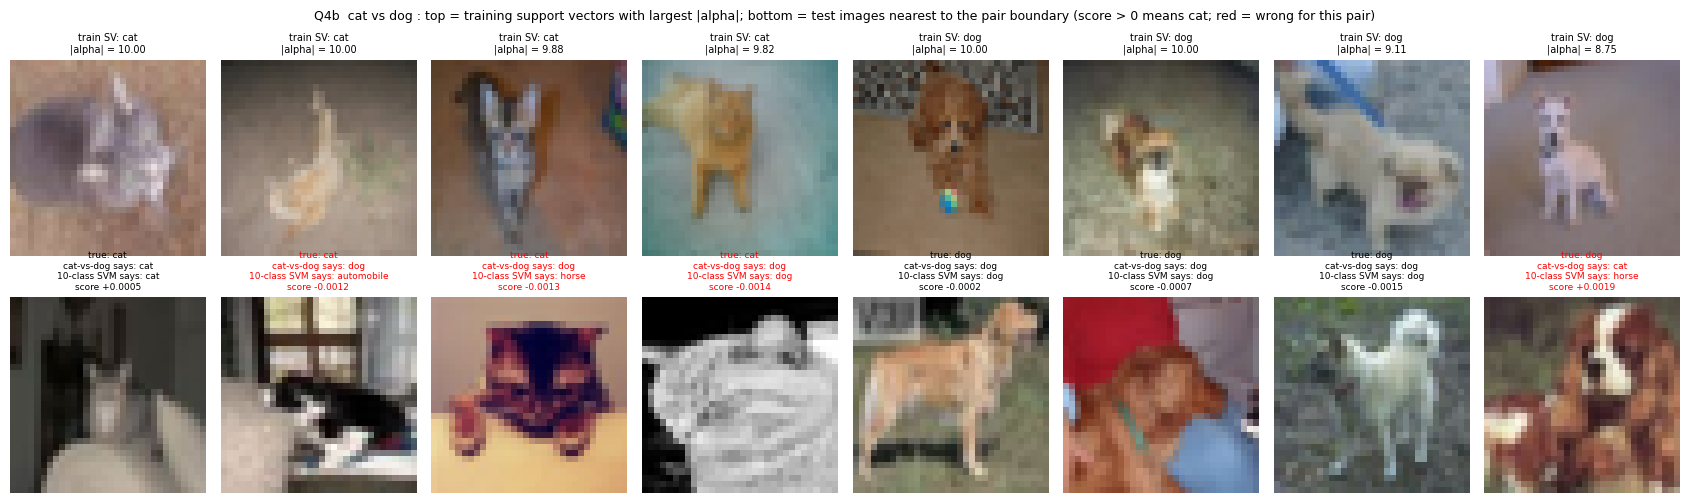

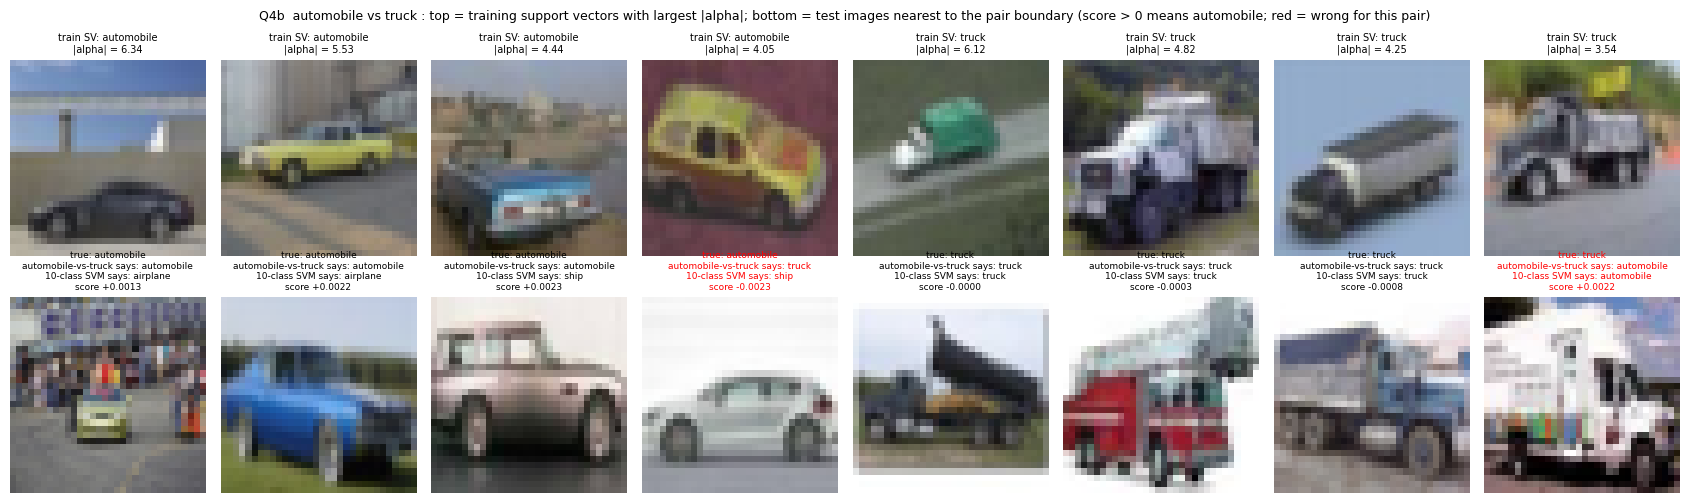

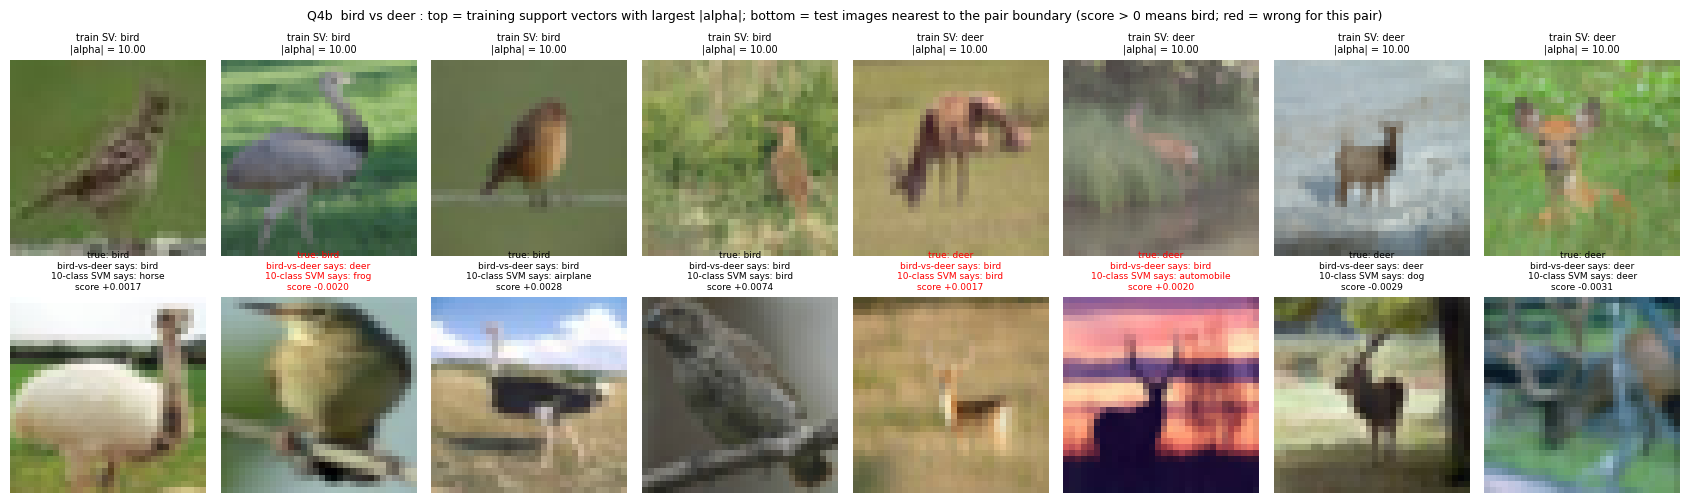

In [25]:
 #2) Q4(b): decision scores with 4 decimals + the answer of the pair classifier next to the 10-class answer
for (a, b) in hard_pairs:
    s = S_te[:, pair_col[(a, b)]]
    if s[y_test == a].mean() < s[y_test == b].mean():
        s = -s                                   # positive = class a
    sv_a, coef_a, sv_b, coef_b = pair_svs(a, b)
    fig, axs = plt.subplots(2, 8, figsize=(17, 5.2))
    sv_show = []
    for cls, svs, cf in [(a, sv_a, coef_a), (b, sv_b, coef_b)]:
        for o in np.argsort(-cf)[:4]:
            sv_show.append((cls, int(svs[o]), float(cf[o])))
    for j, (cls, sv, cf) in enumerate(sv_show):
        axs[0, j].imshow(x_train[svm_idx[final_svm.support_[sv]]]); axs[0, j].axis("off")
        axs[0, j].set_title("train SV: %s\n|alpha| = %.2f" % (class_names[cls], cf), fontsize=7)
    near = []
    for cls in (a, b):
        idx_c = np.where(y_test == cls)[0]
        near += list(idx_c[np.argsort(np.abs(s[idx_c]))[:4]])
    for j, i in enumerate(near):
        pair_says = class_names[a] if s[i] > 0 else class_names[b]
        wrong_pair = pair_says != class_names[y_test[i]]
        axs[1, j].imshow(x_test[i]); axs[1, j].axis("off")
        axs[1, j].set_title("true: %s\n%s-vs-%s says: %s\n10-class SVM says: %s\nscore %+.4f" %
                            (class_names[y_test[i]], class_names[a], class_names[b], pair_says, class_names[pred_te[i]], s[i]),
                            fontsize=6.5, color="red" if wrong_pair else "black")
    fig.suptitle("Q4b  %s vs %s : top = training support vectors with largest |alpha|; bottom = test images nearest to the pair boundary (score > 0 means %s; red = wrong for this pair)" %
                 (class_names[a], class_names[b], class_names[a]), fontsize=9)
    save_show("q4b_pair_%s_vs_%s" % (class_names[a], class_names[b]))
